   # Brain Tumour Detection: using YOLO11n
   Data audit (duplicate removal, label cleaning, group-level split) → training → test evaluation → error analysis.
   

In [1]:
import torch, platform, subprocess, sys

print("=" * 60)
print("ENVIRONMENT DIAGNOSTICS")
print("=" * 60)
print(f"Python version   : {platform.python_version()}")
print(f"PyTorch version  : {torch.__version__}")
print(f"CUDA available   : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU name         : {torch.cuda.get_device_name(0)}")
    total_mem = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"GPU total memory : {total_mem:.2f} GB")
    print(f"CUDA version     : {torch.version.cuda}")
else:
    print("!! No GPU detected. In Colab: Runtime -> Change runtime type -> GPU.")
    print("   Training from scratch (no pretrained weights) on CPU is not practical —")
    print("   stop here and enable a GPU runtime before proceeding.")

ENVIRONMENT DIAGNOSTICS
Python version   : 3.12.13
PyTorch version  : 2.10.0+cu128
CUDA available   : True
GPU name         : Tesla T4
GPU total memory : 14.56 GB
CUDA version     : 12.8


In [2]:

!pip install -q kagglehub opencv-python-headless pillow matplotlib pandas seaborn

In [3]:
import random
import numpy as np

SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print(f"Seed set to {SEED}")

Seed set to 42


In [4]:
import kagglehub

DATASET_SLUG = "ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes"
dataset_path = kagglehub.dataset_download(DATASET_SLUG)
print("Dataset downloaded to:", dataset_path)

Dataset downloaded to: /kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes


In [5]:
import os

def print_tree(root, max_depth=4, max_entries_per_dir=15):
    root = os.path.abspath(root)
    for dirpath, dirnames, filenames in os.walk(root):
        depth = dirpath[len(root):].count(os.sep)
        if depth > max_depth:
            dirnames[:] = []
            continue
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath) or dirpath}/")
        sub_indent = "  " * (depth + 1)
        shown = filenames[:max_entries_per_dir]
        for f in shown:
            print(f"{sub_indent}{f}")
        if len(filenames) > max_entries_per_dir:
            print(f"{sub_indent}... (+{len(filenames) - max_entries_per_dir} more files)")

print_tree(dataset_path)

mri-for-brain-tumor-with-bounding-boxes/
  Val/
    Pituitary/
      labels/
        Tr-pi_0818.txt
        Tr-pi_0596.txt
        Tr-pi_1428.txt
        Tr-pi_0540.txt
        Tr-pi_0532.txt
        Tr-pi_0840.txt
        Tr-pi_1251.txt
        Tr-pi_0972.txt
        Tr-pi_0470.txt
        Tr-pi_0999.txt
        Tr-pi_1117.txt
        Tr-pi_0902.txt
        Tr-pi_1448.txt
        Tr-pi_0525.txt
        Tr-pi_0354.txt
        ... (+121 more files)
      images/
        Tr-pi_0532.jpg
        Tr-pi_0972.jpg
        Tr-pi_0818.jpg
        Tr-pi_0605.jpg
        Tr-pi_0339.jpg
        p (723).jpg
        Tr-pi_1200.jpg
        Tr-pi_0588.jpg
        Tr-pi_0935.jpg
        Tr-pi_1202.jpg
        Tr-pi_1276.jpg
        Tr-pi_0194.jpg
        Te-pi_0018.jpg
        Te-pi_0021.jpg
        Tr-pi_1053.jpg
        ... (+121 more files)
    No Tumor/
      labels/
        image(209).txt
        image(274).txt
        Tr-no_0492.txt
        image(293).txt
        Tr-no_0328.txt
        image(173).

In [6]:
from collections import defaultdict
from pathlib import Path

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
LABEL_EXTS = {".txt"}
CONFIG_NAMES = {"data.yaml", "data.yml", "classes.txt", "notes.json", "README.dataset.txt", "README.roboflow.txt"}

all_files = []
for dirpath, _, filenames in os.walk(dataset_path):
    for f in filenames:
        all_files.append(Path(dirpath) / f)

images_by_split = defaultdict(list)
labels_by_split = defaultdict(list)
config_files = []
other_files = []

def infer_split(path: Path):
    parts = [p.lower() for p in path.parts]
    for candidate in ("train", "training"):
        if candidate in parts:
            return "train"
    for candidate in ("valid", "val", "validation"):
        if candidate in parts:
            return "valid"
    for candidate in ("test", "testing"):
        if candidate in parts:
            return "test"
    return "UNSPLIT"

for f in all_files:
    ext = f.suffix.lower()
    if f.name in CONFIG_NAMES:
        config_files.append(f)
    elif ext in IMAGE_EXTS:
        images_by_split[infer_split(f)].append(f)
    elif ext in LABEL_EXTS:
        labels_by_split[infer_split(f)].append(f)
    else:
        other_files.append(f)

print("=" * 60)
print("FILE INVENTORY")
print("=" * 60)
print(f"Total files found: {len(all_files)}")
print()
print("Images by split:")
for split, files in images_by_split.items():
    print(f"  {split:10s}: {len(files)}")
print()
print("Label (.txt) files by split:")
for split, files in labels_by_split.items():
    print(f"  {split:10s}: {len(files)}")
print()
print("Config/metadata files found:")
for f in config_files:
    print(f"  {f}")
print()
print(f"Other/unclassified files: {len(other_files)}")
for f in other_files[:20]:
    print(f"  {f}")
if len(other_files) > 20:
    print(f"  ... (+{len(other_files) - 20} more)")

FILE INVENTORY
Total files found: 10498

Images by split:
  valid     : 512
  train     : 4737

Label (.txt) files by split:
  valid     : 512
  train     : 4737

Config/metadata files found:

Other/unclassified files: 0


In [7]:
import yaml

classes = None
for cfg in config_files:
    if cfg.suffix in (".yaml", ".yml"):
        try:
            with open(cfg) as fh:
                data = yaml.safe_load(fh)
            print(f"Loaded {cfg}:")
            print(data)
            if isinstance(data, dict) and "names" in data:
                classes = data["names"]
        except Exception as e:
            print(f"Could not parse {cfg}: {e}")
    elif cfg.name == "classes.txt":
        with open(cfg) as fh:
            classes = [line.strip() for line in fh if line.strip()]
        print(f"Loaded classes.txt: {classes}")

if classes is None:
    print("No data.yaml/classes.txt found (or none parsed successfully).")
    print("Class names will need to be inferred from folder names or label file class IDs")
    print("in Section 3 — do not hardcode 4 classes until this is confirmed.")
else:
    print()
    print(f"CLASSES DISCOVERED: {classes}")
    print(f"NUMBER OF CLASSES: {len(classes)}")

No data.yaml/classes.txt found (or none parsed successfully).
Class names will need to be inferred from folder names or label file class IDs
in Section 3 — do not hardcode 4 classes until this is confirmed.


In [8]:
for split in images_by_split:
    n_img = len(images_by_split[split])
    n_lbl = len(labels_by_split.get(split, []))
    flag = "  <-- MISMATCH" if n_img != n_lbl else ""
    print(f"{split:10s}: {n_img} images, {n_lbl} label files{flag}")

total_images = sum(len(v) for v in images_by_split.values())
print()
print(f"TOTAL IMAGES ACROSS ALL SPLITS: {total_images}")
print("Compare this against the 5,246 / 5,249 figures from different sources — ")
print("this printed number is the one to trust.")

valid     : 512 images, 512 label files
train     : 4737 images, 4737 label files

TOTAL IMAGES ACROSS ALL SPLITS: 5249
Compare this against the 5,246 / 5,249 figures from different sources — 
this printed number is the one to trust.


In [9]:
from collections import defaultdict
from pathlib import Path

def find_leaf_dirs(root):
    """A 'leaf' is any directory containing both an images/ and labels/ subfolder.
    Its own name is the class; its ancestors tell us the split."""
    leaves = []
    for dirpath, dirnames, _ in os.walk(root):
        if "images" in dirnames and "labels" in dirnames:
            leaves.append(Path(dirpath))
    return leaves

def infer_split_from_path(path: Path):
    parts = [p.lower() for p in path.parts]
    for c in ("train", "training"):
        if c in parts:
            return "train"
    for c in ("valid", "val", "validation"):
        if c in parts:
            return "valid"
    for c in ("test", "testing"):
        if c in parts:
            return "test"
    return "UNSPLIT"

leaf_dirs = find_leaf_dirs(dataset_path)
print(f"Found {len(leaf_dirs)} class/split leaf directories:\n")

index = defaultdict(lambda: defaultdict(dict))  # index[split][class] = {"images":[...], "labels":[...]}

for leaf in leaf_dirs:
    split = infer_split_from_path(leaf)
    class_name = leaf.name  # e.g. "Glioma", "No Tumor"
    img_files = sorted((leaf / "images").glob("*"))
    lbl_files = sorted((leaf / "labels").glob("*"))
    index[split][class_name] = {"images": img_files, "labels": lbl_files}
    print(f"  [{split:5s}] {class_name:12s}: {len(img_files):4d} images, {len(lbl_files):4d} labels")

CLASS_NAMES = sorted({cls for split_dict in index.values() for cls in split_dict})
print(f"\nCanonical class list (alphabetical, since no data.yaml exists): {CLASS_NAMES}")
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
print(f"Class-to-ID mapping we will enforce ourselves: {CLASS_TO_ID}")

Found 8 class/split leaf directories:

  [valid] Pituitary   :  136 images,  136 labels
  [valid] No Tumor    :  100 images,  100 labels
  [valid] Meningioma  :  140 images,  140 labels
  [valid] Glioma      :  136 images,  136 labels
  [train] Pituitary   : 1424 images, 1424 labels
  [train] No Tumor    :  711 images,  711 labels
  [train] Meningioma  : 1449 images, 1449 labels
  [train] Glioma      : 1153 images, 1153 labels

Canonical class list (alphabetical, since no data.yaml exists): ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
Class-to-ID mapping we will enforce ourselves: {'Glioma': 0, 'Meningioma': 1, 'No Tumor': 2, 'Pituitary': 3}


In [10]:
issues = defaultdict(list)  # issue_type -> list of (split, class, filepath, detail)
class_id_usage = defaultdict(set)  # (split, class) -> set of raw class-ids found in its .txt files
empty_label_count = defaultdict(int)  # (split, class) -> count of empty label files
box_count_per_image = []  # for distribution later

for split, class_dict in index.items():
    for class_name, files in class_dict.items():
        for lbl_path in files["labels"]:
            with open(lbl_path) as f:
                lines = [l.strip() for l in f if l.strip()]

            if len(lines) == 0:
                empty_label_count[(split, class_name)] += 1
                box_count_per_image.append(0)
                continue

            box_count_per_image.append(len(lines))

            for line in lines:
                parts = line.split()
                if len(parts) != 5:
                    issues["malformed_line"].append((split, class_name, lbl_path, line))
                    continue
                try:
                    cid = int(parts[0])
                    x, y, w, h = map(float, parts[1:])
                except ValueError:
                    issues["non_numeric"].append((split, class_name, lbl_path, line))
                    continue

                class_id_usage[(split, class_name)].add(cid)

                if cid < 0:
                    issues["negative_class_id"].append((split, class_name, lbl_path, line))
                if any(v < 0 for v in (x, y, w, h)):
                    issues["negative_coord"].append((split, class_name, lbl_path, line))
                if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
                    issues["out_of_range_coord"].append((split, class_name, lbl_path, line))
                # box extends outside image bounds
                if (x - w / 2 < -1e-6) or (x + w / 2 > 1 + 1e-6) or (y - h / 2 < -1e-6) or (y + h / 2 > 1 + 1e-6):
                    issues["box_outside_bounds"].append((split, class_name, lbl_path, line))

print("=" * 60)
print("LABEL VALIDATION REPORT")
print("=" * 60)
for issue_type, entries in issues.items():
    print(f"{issue_type:25s}: {len(entries)} occurrences")
    for e in entries[:3]:
        print(f"    e.g. {e}")
if not issues:
    print("No malformed/out-of-range/negative annotations found.")

print()
print("Class-ID values actually used inside each folder's .txt files:")
for key, ids in sorted(class_id_usage.items()):
    print(f"  {key}: {sorted(ids)}")
print()
print("Empty label files per (split, class) — check especially 'No Tumor':")
for key, count in sorted(empty_label_count.items()):
    total = len(index[key[0]][key[1]]["labels"])
    print(f"  {key}: {count}/{total} empty")

LABEL VALIDATION REPORT
No malformed/out-of-range/negative annotations found.

Class-ID values actually used inside each folder's .txt files:
  ('train', 'Glioma'): [0, 1, 3]
  ('train', 'Meningioma'): [0, 1, 3]
  ('train', 'No Tumor'): [2]
  ('train', 'Pituitary'): [1, 3]
  ('valid', 'Glioma'): [0, 3]
  ('valid', 'Meningioma'): [1, 3]
  ('valid', 'No Tumor'): [2]
  ('valid', 'Pituitary'): [3]

Empty label files per (split, class) — check especially 'No Tumor':
  ('valid', 'Glioma'): 1/136 empty


In [11]:
from collections import Counter

print("=" * 60)
print("PER-FOLDER CLASS-ID FREQUENCY (how often does a folder's labels")
print("disagree with the folder's own name?)")
print("=" * 60)

mismatch_examples = defaultdict(list)  # (split, class_name) -> list of (img_path, lbl_path, ids_in_file)

for split, class_dict in index.items():
    for class_name, files in class_dict.items():
        expected_id = CLASS_TO_ID[class_name]
        id_counter = Counter()
        n_files_with_any_mismatch = 0
        for lbl_path in files["labels"]:
            with open(lbl_path) as f:
                lines = [l.strip() for l in f if l.strip()]
            ids_in_file = [int(l.split()[0]) for l in lines]
            id_counter.update(ids_in_file)
            if any(i != expected_id for i in ids_in_file):
                n_files_with_any_mismatch += 1
                if len(mismatch_examples[(split, class_name)]) < 5:
                    img_path = files["images"][files["labels"].index(lbl_path)] if False else None
                    mismatch_examples[(split, class_name)].append((lbl_path, ids_in_file))

        total_boxes = sum(id_counter.values())
        expected_boxes = id_counter.get(expected_id, 0)
        pct_correct = 100 * expected_boxes / total_boxes if total_boxes else float("nan")
        print(f"[{split:5s}] {class_name:12s} (expected id={expected_id}): "
              f"{dict(sorted(id_counter.items()))}  "
              f"-> {pct_correct:.1f}% of boxes match folder, "
              f"{n_files_with_any_mismatch}/{len(files['labels'])} files have >=1 mismatched box")

# Locate the one empty label file in valid/Glioma
print()
print("Empty label file(s) in valid/Glioma:")
for lbl_path in index["valid"]["Glioma"]["labels"]:
    if os.path.getsize(lbl_path) == 0 or len(open(lbl_path).read().strip()) == 0:
        print(f"  {lbl_path}")
        # find the matching image (same stem)
        stem = lbl_path.stem
        matches = [p for p in index["valid"]["Glioma"]["images"] if p.stem == stem]
        print(f"  matching image: {matches}")

PER-FOLDER CLASS-ID FREQUENCY (how often does a folder's labels
disagree with the folder's own name?)
[valid] Pituitary    (expected id=3): {3: 143}  -> 100.0% of boxes match folder, 0/136 files have >=1 mismatched box
[valid] No Tumor     (expected id=2): {2: 100}  -> 100.0% of boxes match folder, 0/100 files have >=1 mismatched box
[valid] Meningioma   (expected id=1): {1: 142, 3: 6}  -> 95.9% of boxes match folder, 6/140 files have >=1 mismatched box
[valid] Glioma       (expected id=0): {0: 153, 3: 12}  -> 92.7% of boxes match folder, 12/136 files have >=1 mismatched box
[train] Pituitary    (expected id=3): {1: 1, 3: 1520}  -> 99.9% of boxes match folder, 1/1424 files have >=1 mismatched box
[train] No Tumor     (expected id=2): {2: 711}  -> 100.0% of boxes match folder, 0/711 files have >=1 mismatched box
[train] Meningioma   (expected id=1): {0: 2, 1: 1478, 3: 103}  -> 93.4% of boxes match folder, 100/1449 files have >=1 mismatched box
[train] Glioma       (expected id=0): {0: 1

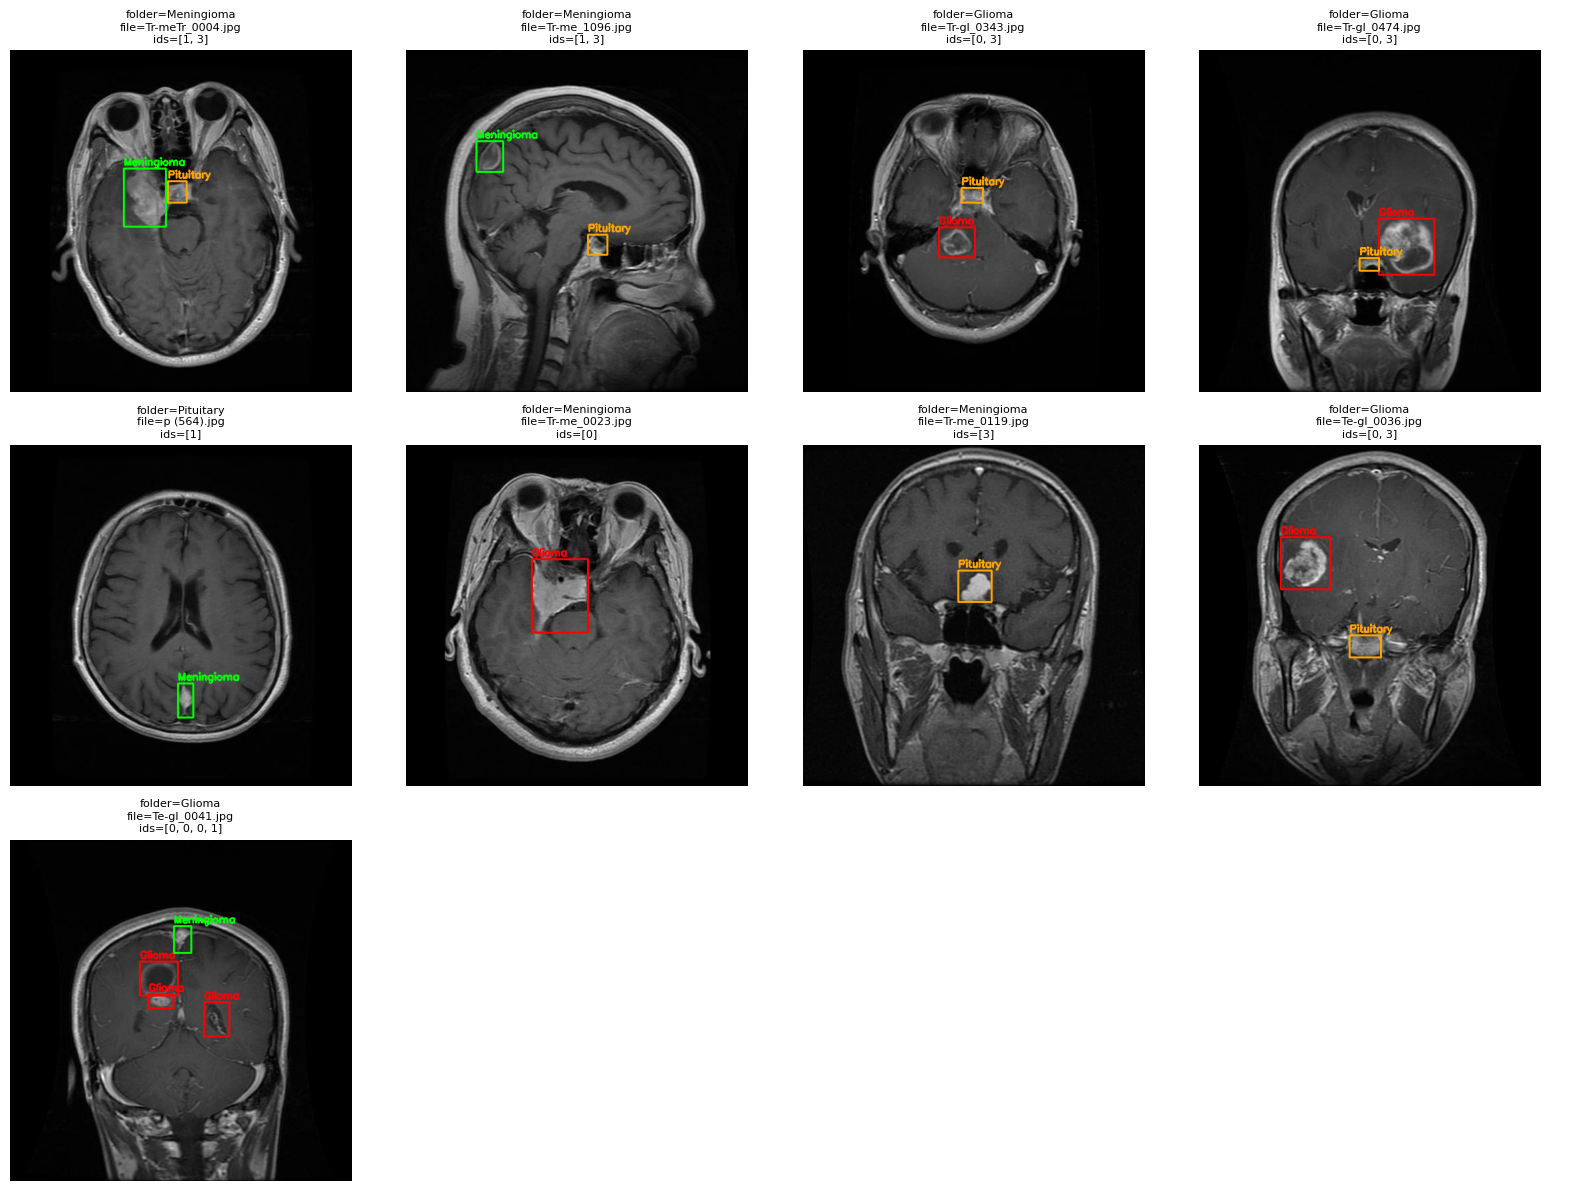

In [12]:
import cv2
import matplotlib.pyplot as plt

def load_boxes(lbl_path, img_shape):
    h, w = img_shape[:2]
    boxes = []
    with open(lbl_path) as f:
        for line in f:
            parts = line.split()
            if len(parts) != 5:
                continue
            cid, x, y, bw, bh = int(parts[0]), *map(float, parts[1:])
            x1 = int((x - bw / 2) * w)
            y1 = int((y - bh / 2) * h)
            x2 = int((x + bw / 2) * w)
            y2 = int((y + bh / 2) * h)
            boxes.append((cid, x1, y1, x2, y2))
    return boxes

ID_TO_CLASS = {v: k for k, v in CLASS_TO_ID.items()}
COLORS = {0: (255, 0, 0), 1: (0, 255, 0), 2: (0, 0, 255), 3: (255, 165, 0)}

# Pick a few mismatch examples across different folders to actually look at
to_show = []
for (split, class_name), examples in mismatch_examples.items():
    for lbl_path, ids_in_file in examples[:2]:
        stem = lbl_path.stem
        img_matches = [p for p in index[split][class_name]["images"] if p.stem == stem]
        if img_matches:
            to_show.append((split, class_name, img_matches[0], lbl_path, ids_in_file))

to_show = to_show[:12]
n = len(to_show)
cols = 4
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4))
axes = axes.flatten() if n > 1 else [axes]

for ax, (split, class_name, img_path, lbl_path, ids_in_file) in zip(axes, to_show):
    img = cv2.imread(str(img_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    boxes = load_boxes(lbl_path, img.shape)
    for cid, x1, y1, x2, y2 in boxes:
        color = COLORS.get(cid, (255, 255, 255))
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        cv2.putText(img, ID_TO_CLASS.get(cid, str(cid)), (x1, max(y1 - 5, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
    ax.imshow(img)
    ax.set_title(f"folder={class_name}\nfile={img_path.name}\nids={ids_in_file}", fontsize=8)
    ax.axis("off")

for ax in axes[len(to_show):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Mismatched 'Pituitary' boxes found in Glioma/Meningioma folders: 273
  center x: mean=0.488, std=0.042
  center y: mean=0.601, std=0.081

Genuine 'Pituitary' boxes in the Pituitary folder: 1663
  center x: mean=0.479, std=0.049
  center y: mean=0.510, std=0.079


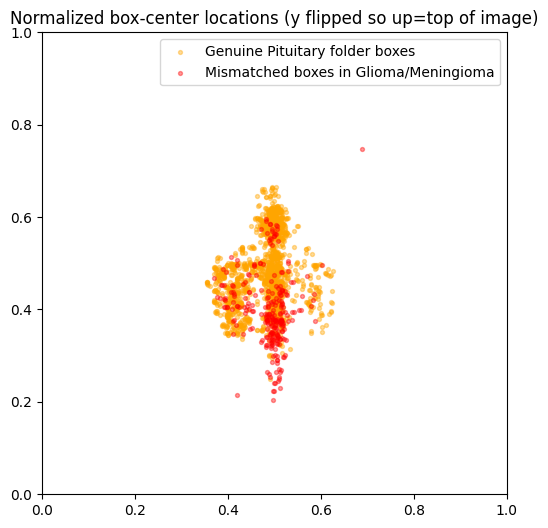

In [13]:
import numpy as np

pituitary_mismatch_centers = []  # (x_center, y_center) normalized, for id==3 boxes found inside Glioma/Meningioma folders
correct_pituitary_centers = []   # id==3 boxes inside the actual Pituitary folder, for comparison

for split, class_name in [("train", "Glioma"), ("valid", "Glioma"), ("train", "Meningioma"), ("valid", "Meningioma")]:
    for lbl_path in index[split][class_name]["labels"]:
        with open(lbl_path) as f:
            for line in f:
                parts = line.split()
                if len(parts) == 5 and int(parts[0]) == 3:
                    pituitary_mismatch_centers.append((float(parts[1]), float(parts[2])))

for split in ["train", "valid"]:
    for lbl_path in index[split]["Pituitary"]["labels"]:
        with open(lbl_path) as f:
            for line in f:
                parts = line.split()
                if len(parts) == 5 and int(parts[0]) == 3:
                    correct_pituitary_centers.append((float(parts[1]), float(parts[2])))

mismatch_arr = np.array(pituitary_mismatch_centers)
correct_arr = np.array(correct_pituitary_centers)

print(f"Mismatched 'Pituitary' boxes found in Glioma/Meningioma folders: {len(mismatch_arr)}")
print(f"  center x: mean={mismatch_arr[:,0].mean():.3f}, std={mismatch_arr[:,0].std():.3f}")
print(f"  center y: mean={mismatch_arr[:,1].mean():.3f}, std={mismatch_arr[:,1].std():.3f}")
print()
print(f"Genuine 'Pituitary' boxes in the Pituitary folder: {len(correct_arr)}")
print(f"  center x: mean={correct_arr[:,0].mean():.3f}, std={correct_arr[:,0].std():.3f}")
print(f"  center y: mean={correct_arr[:,1].mean():.3f}, std={correct_arr[:,1].std():.3f}")

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(correct_arr[:, 0], 1 - correct_arr[:, 1], s=8, alpha=0.4, label="Genuine Pituitary folder boxes", color="orange")
ax.scatter(mismatch_arr[:, 0], 1 - mismatch_arr[:, 1], s=8, alpha=0.4, label="Mismatched boxes in Glioma/Meningioma", color="red")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("Normalized box-center locations (y flipped so up=top of image)")
ax.legend()
plt.show()

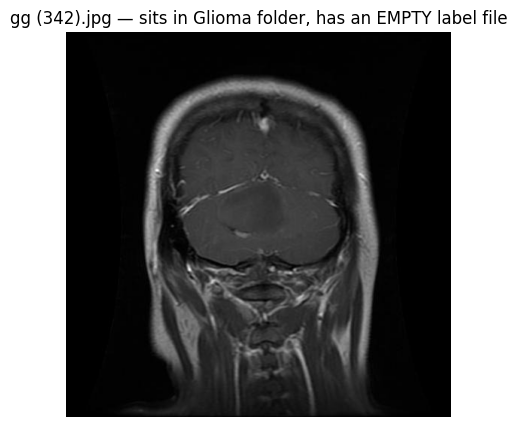

In [14]:
img = cv2.imread(str(index["valid"]["Glioma"]["images"][
    [p.stem for p in index["valid"]["Glioma"]["images"]].index("gg (342)")
]))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title("gg (342).jpg — sits in Glioma folder, has an EMPTY label file")
plt.axis("off")
plt.show()

In [15]:
empty_label_paths = []

for split, class_dict in index.items():
    for class_name, files in class_dict.items():
        for lbl_path in files["labels"]:
            content = open(lbl_path).read().strip()
            if content == "":
                empty_label_paths.append((split, class_name, lbl_path))

print(f"Total empty label files across entire dataset: {len(empty_label_paths)}")
print()
by_class = Counter((s, c) for s, c, _ in empty_label_paths)
for key, count in sorted(by_class.items()):
    total = len(index[key[0]][key[1]]["labels"])
    print(f"  {key}: {count}/{total} empty ({100*count/total:.1f}%)")

Total empty label files across entire dataset: 1

  ('valid', 'Glioma'): 1/136 empty (0.7%)


In [16]:
from PIL import Image

corrupt_images = []
dims_seen = Counter()
mode_seen = Counter()

all_image_paths = [(s, c, p) for s, cd in index.items() for c, files in cd.items() for p in files["images"]]
print(f"Checking {len(all_image_paths)} images...")

for split, class_name, img_path in all_image_paths:
    try:
        with Image.open(img_path) as im:
            im.verify()
        with Image.open(img_path) as im:
            dims_seen[im.size] += 1
            mode_seen[im.mode] += 1
    except Exception as e:
        corrupt_images.append((split, class_name, img_path, str(e)))

print(f"\nCorrupt/unreadable images: {len(corrupt_images)}")
for entry in corrupt_images[:10]:
    print(f"  {entry}")

print(f"\nTop 10 image dimensions found:")
for dims, count in dims_seen.most_common(10):
    print(f"  {dims}: {count} images")

print(f"\nColor modes found: {dict(mode_seen)}")

Checking 5249 images...

Corrupt/unreadable images: 0

Top 10 image dimensions found:
  (512, 512): 4206 images
  (225, 225): 119 images
  (630, 630): 66 images
  (442, 442): 42 images
  (236, 236): 33 images
  (256, 256): 25 images
  (201, 251): 23 images
  (201, 250): 22 images
  (214, 236): 18 images
  (468, 444): 15 images

Color modes found: {'RGB': 4247, 'L': 998, 'RGBA': 3, 'P': 1}


In [17]:
import shutil

def clean_label_file(lbl_path: Path, valid_class_id: int):
    """Keep only boxes whose class matches the folder's own class.
    This removes the spurious pituitary-gland-landmark boxes confirmed above.
    Returns (kept, removed) counts."""
    with open(lbl_path) as f:
        lines = [l.strip() for l in f if l.strip()]
    kept_lines = [l for l in lines if int(l.split()[0]) == valid_class_id]
    removed = len(lines) - len(kept_lines)
    return kept_lines, removed

# Dry run first — report what WOULD be removed, don't write anything yet
total_removed = 0
total_files_affected = 0
removal_report = defaultdict(int)

for split, class_dict in index.items():
    for class_name, files in class_dict.items():
        expected_id = CLASS_TO_ID[class_name]
        for lbl_path in files["labels"]:
            kept, removed = clean_label_file(lbl_path, expected_id)
            if removed > 0:
                total_removed += removed
                total_files_affected += 1
                removal_report[(split, class_name)] += removed

print("DRY RUN — no files modified yet.")
print(f"Total spurious boxes that would be removed: {total_removed}")
print(f"Total files affected: {total_files_affected}")
print()
for key, count in sorted(removal_report.items()):
    print(f"  {key}: {count} boxes removed")

DRY RUN — no files modified yet.
Total spurious boxes that would be removed: 279
Total files affected: 272

  ('train', 'Glioma'): 155 boxes removed
  ('train', 'Meningioma'): 105 boxes removed
  ('train', 'Pituitary'): 1 boxes removed
  ('valid', 'Glioma'): 12 boxes removed
  ('valid', 'Meningioma'): 6 boxes removed


In [18]:
dims_by_class = defaultdict(Counter)
mode_by_class = defaultdict(Counter)

for split, class_dict in index.items():
    for class_name, files in class_dict.items():
        for img_path in files["images"]:
            with Image.open(img_path) as im:
                dims_by_class[class_name][im.size] += 1
                mode_by_class[class_name][im.mode] += 1

print("Dimension distribution per class (top 5 each):")
for class_name, counter in dims_by_class.items():
    total = sum(counter.values())
    print(f"\n  {class_name} (n={total}):")
    for dims, count in counter.most_common(5):
        print(f"    {dims}: {count} ({100*count/total:.1f}%)")

print("\n" + "=" * 60)
print("Color mode distribution per class:")
for class_name, counter in mode_by_class.items():
    total = sum(counter.values())
    print(f"  {class_name}: {dict(counter)}  (n={total})")

Dimension distribution per class (top 5 each):

  Pituitary (n=1560):
    (512, 512): 1515 (97.1%)
    (256, 256): 22 (1.4%)
    (474, 474): 4 (0.3%)
    (202, 202): 2 (0.1%)
    (201, 210): 2 (0.1%)

  No Tumor (n=811):
    (225, 225): 109 (13.4%)
    (630, 630): 66 (8.1%)
    (442, 442): 34 (4.2%)
    (236, 236): 33 (4.1%)
    (201, 250): 22 (2.7%)

  Meningioma (n=1589):
    (512, 512): 1386 (87.2%)
    (225, 225): 10 (0.6%)
    (442, 442): 7 (0.4%)
    (455, 500): 6 (0.4%)
    (554, 554): 4 (0.3%)

  Glioma (n=1289):
    (512, 512): 1289 (100.0%)

Color mode distribution per class:
  Pituitary: {'RGB': 1339, 'L': 221}  (n=1560)
  No Tumor: {'RGB': 792, 'L': 15, 'RGBA': 3, 'P': 1}  (n=811)
  Meningioma: {'RGB': 1297, 'L': 292}  (n=1589)
  Glioma: {'L': 470, 'RGB': 819}  (n=1289)


In [19]:
CLEAN_ROOT = Path("/content/dataset_clean")
if CLEAN_ROOT.exists():
    shutil.rmtree(CLEAN_ROOT)

files_written = 0
boxes_removed_total = 0

for split, class_dict in index.items():
    for class_name, files in class_dict.items():
        expected_id = CLASS_TO_ID[class_name]
        img_dst = CLEAN_ROOT / split / class_name / "images"
        lbl_dst = CLEAN_ROOT / split / class_name / "labels"
        img_dst.mkdir(parents=True, exist_ok=True)
        lbl_dst.mkdir(parents=True, exist_ok=True)

        label_by_stem = {p.stem: p for p in files["labels"]}

        for img_path in files["images"]:
            # Normalize to grayscale (kills fake-RGB channel-count shortcut + stray UI-color artifacts),
            # save as .jpg to keep file sizes reasonable, re-encode even already-grayscale images
            # so every file in the clean set has gone through the identical pipeline.
            with Image.open(img_path) as im:
                im_gray = im.convert("L")
                im_gray.save(img_dst / f"{img_path.stem}.jpg", quality=95)

            lbl_path = label_by_stem.get(img_path.stem)
            if lbl_path is None:
                (lbl_dst / f"{img_path.stem}.txt").write_text("")
                continue
            kept_lines, removed = clean_label_file(lbl_path, expected_id)
            boxes_removed_total += removed
            (lbl_dst / lbl_path.name).write_text("\n".join(kept_lines) + ("\n" if kept_lines else ""))
            files_written += 1

print(f"Clean dataset written to: {CLEAN_ROOT}")
print(f"Label files written: {files_written}")
print(f"Total spurious boxes removed: {boxes_removed_total}")
assert boxes_removed_total == total_removed, "Mismatch vs dry run — investigate!"
print("All images normalized to grayscale, spurious Pituitary-landmark boxes removed.")

Clean dataset written to: /content/dataset_clean
Label files written: 5247
Total spurious boxes removed: 279
All images normalized to grayscale, spurious Pituitary-landmark boxes removed.


In [20]:
import numpy as np

true_rgb_count = defaultdict(int)
fake_rgb_count = defaultdict(int)  # R==G==B everywhere, i.e. grayscale content saved in RGB mode
sample_check_n = 0

for split, class_dict in index.items():
    for class_name, files in class_dict.items():
        for img_path in files["images"]:
            with Image.open(img_path) as im:
                if im.mode not in ("RGB", "RGBA"):
                    continue
                arr = np.array(im.convert("RGB"))
                sample_check_n += 1
                if np.array_equal(arr[..., 0], arr[..., 1]) and np.array_equal(arr[..., 1], arr[..., 2]):
                    fake_rgb_count[class_name] += 1
                else:
                    true_rgb_count[class_name] += 1

print(f"Checked {sample_check_n} RGB/RGBA-mode images.\n")
for class_name in CLASS_NAMES:
    fake = fake_rgb_count[class_name]
    real = true_rgb_count[class_name]
    total = fake + real
    if total:
        print(f"  {class_name:12s}: {fake}/{total} ({100*fake/total:.1f}%) are grayscale-saved-as-RGB, "
              f"{real} are genuinely multi-channel")

Checked 4250 RGB/RGBA-mode images.

  Glioma      : 819/819 (100.0%) are grayscale-saved-as-RGB, 0 are genuinely multi-channel
  Meningioma  : 1297/1297 (100.0%) are grayscale-saved-as-RGB, 0 are genuinely multi-channel
  No Tumor    : 762/795 (95.8%) are grayscale-saved-as-RGB, 33 are genuinely multi-channel
  Pituitary   : 1339/1339 (100.0%) are grayscale-saved-as-RGB, 0 are genuinely multi-channel


In [21]:
aspect_by_class = defaultdict(list)

for split, class_dict in index.items():
    for class_name, files in class_dict.items():
        for img_path in files["images"]:
            with Image.open(img_path) as im:
                w, h = im.size
                aspect_by_class[class_name].append(w / h)

print("Aspect ratio (width/height) stats per class:")
for class_name in CLASS_NAMES:
    arr = np.array(aspect_by_class[class_name])
    non_square = np.sum(np.abs(arr - 1.0) > 0.01)
    print(f"  {class_name:12s}: mean={arr.mean():.3f}, std={arr.std():.3f}, "
          f"non-square: {non_square}/{len(arr)} ({100*non_square/len(arr):.1f}%)")

Aspect ratio (width/height) stats per class:
  Glioma      : mean=1.000, std=0.000, non-square: 0/1289 (0.0%)
  Meningioma  : mean=0.994, std=0.055, non-square: 170/1589 (10.7%)
  No Tumor    : mean=0.963, std=0.157, non-square: 505/811 (62.3%)
  Pituitary   : mean=1.000, std=0.007, non-square: 8/1560 (0.5%)


Found 33 genuinely multi-channel No Tumor images


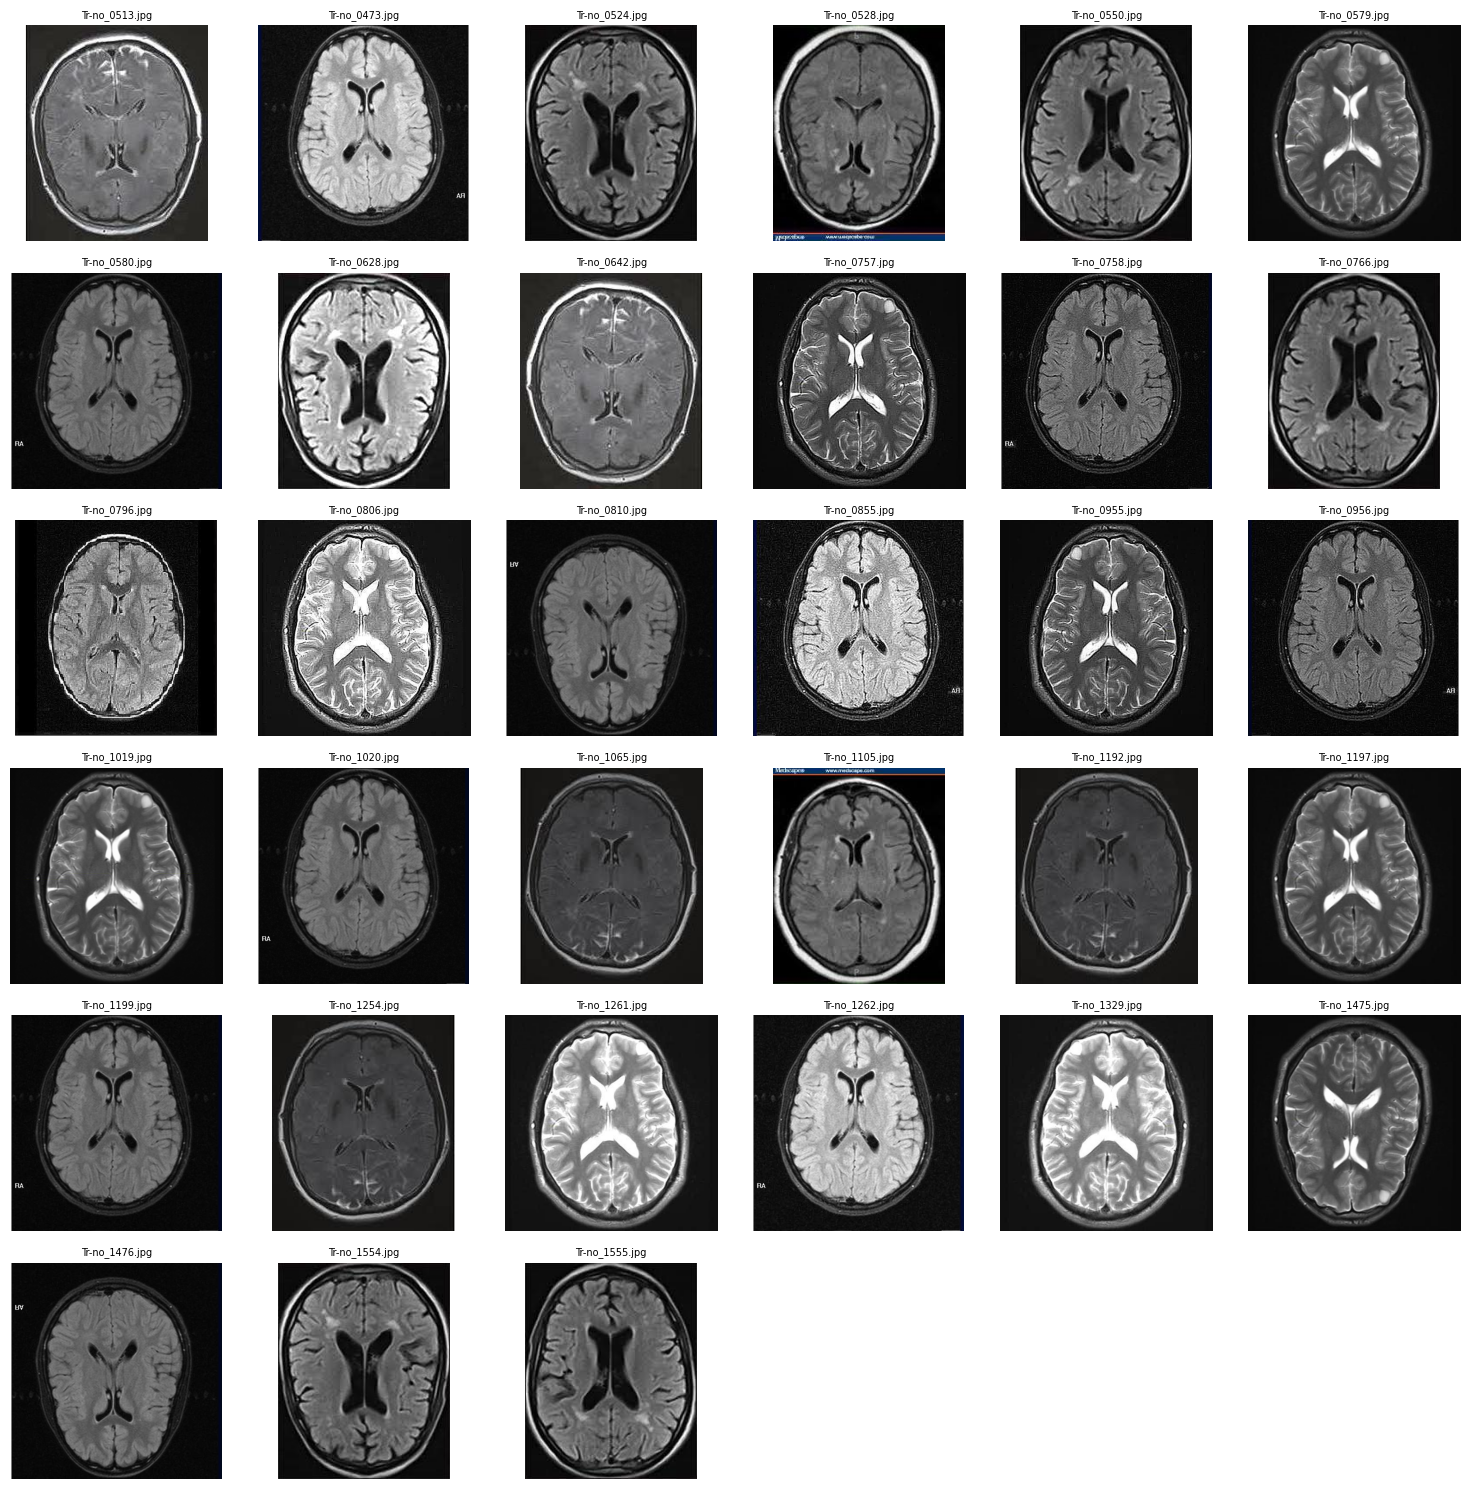

In [22]:
true_rgb_paths = []
for split, class_dict in index.items():
    files = class_dict.get("No Tumor")
    if not files:
        continue
    for img_path in files["images"]:
        with Image.open(img_path) as im:
            if im.mode in ("RGB", "RGBA"):
                arr = np.array(im.convert("RGB"))
                if not (np.array_equal(arr[..., 0], arr[..., 1]) and np.array_equal(arr[..., 1], arr[..., 2])):
                    true_rgb_paths.append(img_path)

print(f"Found {len(true_rgb_paths)} genuinely multi-channel No Tumor images")

n = len(true_rgb_paths)
cols = 6
rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.5, rows * 2.5))
axes = axes.flatten()
for ax, p in zip(axes, true_rgb_paths):
    im = Image.open(p).convert("RGB")
    ax.imshow(im)
    ax.set_title(p.name, fontsize=7)
    ax.axis("off")
for ax in axes[len(true_rgb_paths):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

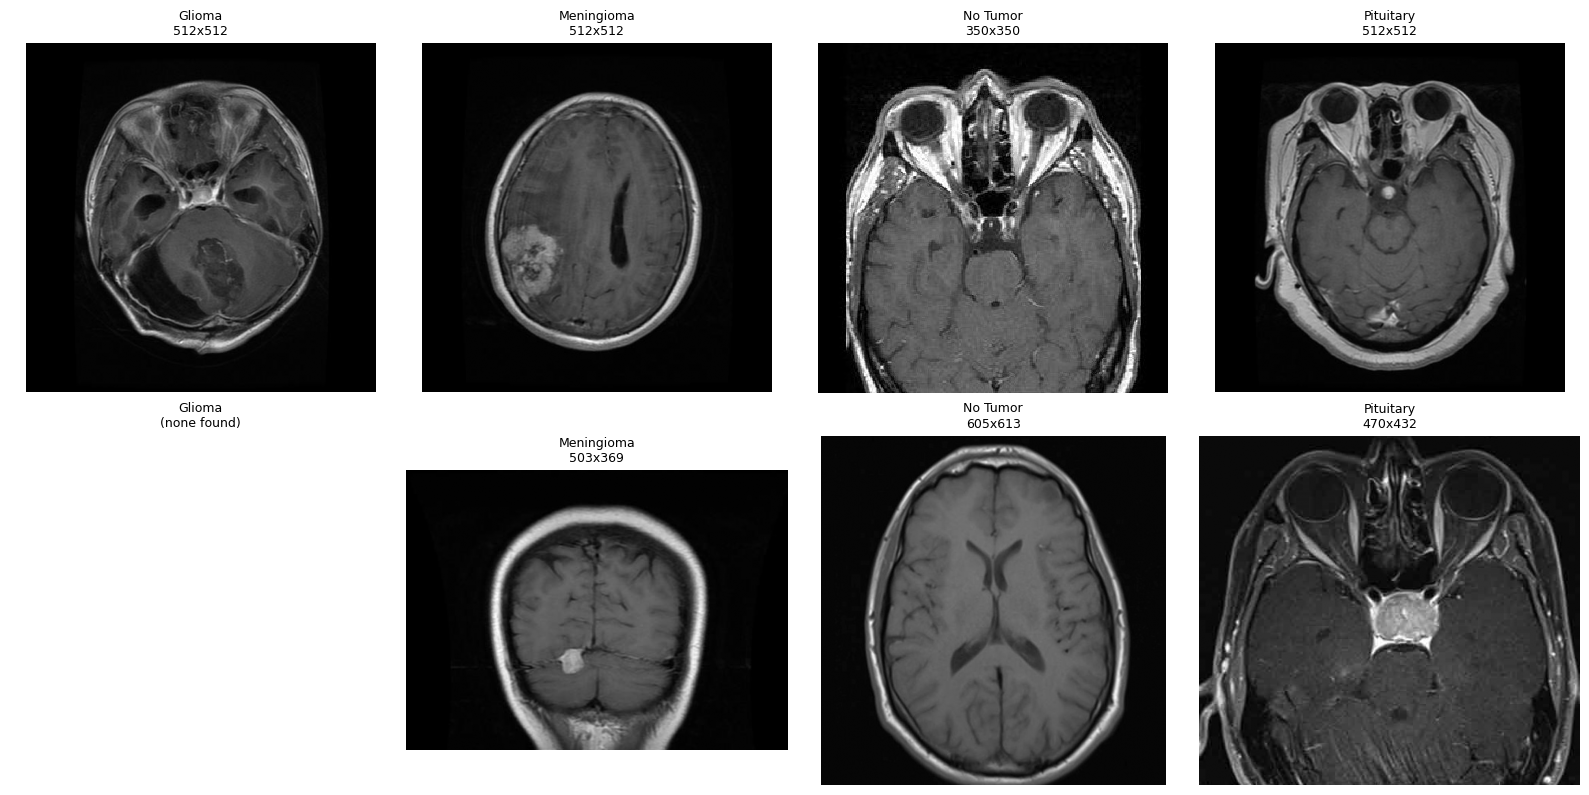

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for col, class_name in enumerate(CLASS_NAMES):
    # one square example, one non-square example if available
    imgs = []
    for split in ("train", "valid"):
        for img_path in index[split][class_name]["images"]:
            with Image.open(img_path) as im:
                w, h = im.size
                is_square = abs(w / h - 1.0) <= 0.01
                imgs.append((is_square, img_path))

    square_ex = next((p for sq, p in imgs if sq), None)
    nonsquare_ex = next((p for sq, p in imgs if not sq), None)

    for row, ex in enumerate([square_ex, nonsquare_ex]):
        ax = axes[row, col]
        if ex is not None:
            im = Image.open(ex).convert("L")
            ax.imshow(im, cmap="gray")
            w, h = im.size
            ax.set_title(f"{class_name}\n{w}x{h}", fontsize=9)
        else:
            ax.set_title(f"{class_name}\n(none found)", fontsize=9)
        ax.axis("off")

axes[0, 0].set_ylabel("square example", fontsize=10)
axes[1, 0].set_ylabel("non-square example", fontsize=10)
plt.tight_layout()
plt.show()

In [24]:
!pip install -q imagehash

In [25]:
import hashlib

def file_md5(path, chunk_size=8192):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

hash_to_paths = defaultdict(list)

for split, class_dict in index.items():
    for class_name, files in class_dict.items():
        for img_path in files["images"]:
            hash_to_paths[file_md5(img_path)].append((split, class_name, img_path))

exact_dupes = {h: paths for h, paths in hash_to_paths.items() if len(paths) > 1}
print(f"Exact duplicate groups found: {len(exact_dupes)}")

cross_split_exact = 0
cross_class_exact = 0
for h, paths in exact_dupes.items():
    splits = {p[0] for p in paths}
    classes = {p[1] for p in paths}
    if len(splits) > 1:
        cross_split_exact += 1
    if len(classes) > 1:
        cross_class_exact += 1

print(f"  of which span train+valid (real leakage): {cross_split_exact}")
print(f"  of which span multiple classes (labeling conflict): {cross_class_exact}")
print()
for h, paths in list(exact_dupes.items())[:5]:
    print(f"  {h}: {paths}")

Exact duplicate groups found: 1228
  of which span train+valid (real leakage): 213
  of which span multiple classes (labeling conflict): 0

  66c75b6f0f44cf5fd92940189e90b61c: [('valid', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/Pituitary/images/Te-pi_0018.jpg')), ('train', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Train/Pituitary/images/p (633).jpg'))]
  a31ab9f92afbaa4543084c7b12151283: [('valid', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/Pituitary/images/Te-pi_0021.jpg')), ('train', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Train/Pituitary/images/p (645).jpg'))]
  af400abcb33c1d5c68bbfdc75666aa3f: [('valid', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/Pituitary/images/Te-pi_0025.jpg')), (

In [26]:
import imagehash

phash_to_paths = defaultdict(list)

for split, class_dict in index.items():
    for class_name, files in class_dict.items():
        for img_path in files["images"]:
            with Image.open(img_path) as im:
                ph = imagehash.phash(im, hash_size=16)  # higher hash_size = more sensitive
            phash_to_paths[ph].append((split, class_name, img_path))

near_dupe_groups = {h: paths for h, paths in phash_to_paths.items() if len(paths) > 1}
print(f"Near-duplicate groups (identical phash): {len(near_dupe_groups)}")

cross_split_near = [(h, paths) for h, paths in near_dupe_groups.items() if len({p[0] for p in paths}) > 1]
print(f"  of which span train+valid: {len(cross_split_near)}")

print("\nFirst 5 cross-split near-duplicate groups (THESE ARE LEAKAGE):")
for h, paths in cross_split_near[:5]:
    print(f"  {paths}")

Near-duplicate groups (identical phash): 1239
  of which span train+valid: 215

First 5 cross-split near-duplicate groups (THESE ARE LEAKAGE):
  [('valid', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/Pituitary/images/Te-pi_0018.jpg')), ('train', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Train/Pituitary/images/p (633).jpg'))]
  [('valid', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/Pituitary/images/Te-pi_0021.jpg')), ('train', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Train/Pituitary/images/p (645).jpg'))]
  [('valid', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/Val/Pituitary/images/Te-pi_0025.jpg')), ('train', 'Pituitary', PosixPath('/kaggle/input/datasets/ahmedsorour1/mri-for-brain-tumor-with-bound

In [27]:
class UnionFind:
    def __init__(self):
        self.parent = {}

    def find(self, x):
        self.parent.setdefault(x, x)
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[ra] = rb

uf = UnionFind()
all_paths = [(s, c, p) for s, cd in index.items() for c, files in cd.items() for p in files["images"]]

for group in exact_dupes.values():
    paths = [p[2] for p in group]
    for p in paths[1:]:
        uf.union(str(paths[0]), str(p))

for group in near_dupe_groups.values():
    paths = [p[2] for p in group]
    for p in paths[1:]:
        uf.union(str(paths[0]), str(p))

# Build final groups
group_members = defaultdict(list)
path_to_meta = {str(p): (s, c) for s, c, p in all_paths}
for s, c, p in all_paths:
    root = uf.find(str(p))
    group_members[root].append(str(p))

total_images = len(all_paths)
total_groups = len(group_members)
print(f"Total images: {total_images}")
print(f"Total unique dedup groups (i.e. true unique scans): {total_groups}")
print(f"Duplication factor: {total_images/total_groups:.2f}x\n")

cross_split_groups = 0
cross_class_groups = 0
group_sizes = Counter()
cross_split_by_class = Counter()

for root, members in group_members.items():
    metas = [path_to_meta[m] for m in members]
    splits = {m[0] for m in metas}
    classes = {m[1] for m in metas}
    group_sizes[len(members)] += 1
    if len(splits) > 1:
        cross_split_groups += 1
        for c in classes:
            cross_split_by_class[c] += 1
    if len(classes) > 1:
        cross_class_groups += 1

print(f"Groups spanning train+valid (leakage): {cross_split_groups}")
print(f"Groups spanning multiple classes (labeling conflict): {cross_class_groups}")
print(f"\nCross-split leakage groups by class: {dict(cross_split_by_class)}")
print(f"\nGroup size distribution: {dict(sorted(group_sizes.items()))}")

# Actual number of valid images that are contaminated (i.e. also appear in train)
contaminated_valid_images = sum(
    1 for root, members in group_members.items()
    if len({path_to_meta[m][0] for m in members}) > 1
    for m in members if path_to_meta[m][0] == "valid"
)
print(f"\nValid-split images that are duplicates of a train image: {contaminated_valid_images}")
for class_name in CLASS_NAMES:
    valid_total = len(index["valid"][class_name]["images"])
    contaminated = sum(
        1 for root, members in group_members.items()
        if len({path_to_meta[m][0] for m in members}) > 1
        for m in members if path_to_meta[m][0] == "valid" and path_to_meta[m][1] == class_name
    )
    print(f"  {class_name:12s}: {contaminated}/{valid_total} valid images contaminated ({100*contaminated/valid_total:.1f}%)")

Total images: 5249
Total unique dedup groups (i.e. true unique scans): 3862
Duplication factor: 1.36x

Groups spanning train+valid (leakage): 215
Groups spanning multiple classes (labeling conflict): 0

Cross-split leakage groups by class: {'Pituitary': 77, 'No Tumor': 52, 'Meningioma': 77, 'Glioma': 9}

Group size distribution: {1: 2623, 2: 1166, 3: 38, 4: 18, 5: 8, 6: 4, 7: 2, 8: 2, 14: 1}

Valid-split images that are duplicates of a train image: 220
  Glioma      : 9/136 valid images contaminated (6.6%)
  Meningioma  : 78/140 valid images contaminated (55.7%)
  No Tumor    : 56/100 valid images contaminated (56.0%)
  Pituitary   : 77/136 valid images contaminated (56.6%)


In [28]:
def pick_canonical(members):
    """Prefer the file whose name looks like the dataset's own convention
    (Tr-xx_NNNN / Te-xx_NNNN) over ad-hoc names (gg (N), m1(N), image(N), p (N)),
    since those look like the 'primary' copies each source's naming scheme produced.
    Falls back to shortest path string for determinism otherwise."""
    def score(p):
        name = Path(p).stem
        return (0 if name.startswith(("Tr-", "Te-")) else 1, len(name))
    return sorted(members, key=score)[0]

dedup_records = []  # list of dicts: {group_id, class_name, img_path, lbl_path}

for root, members in group_members.items():
    metas = [path_to_meta[m] for m in members]
    class_name = metas[0][1]  # confirmed 0 cross-class groups, safe to take first
    canonical = pick_canonical(members)
    canonical_split, canonical_class = path_to_meta[canonical]
    # find its label file from the original index
    lbl_candidates = [p for p in index[canonical_split][canonical_class]["labels"] if p.stem == Path(canonical).stem]
    lbl_path = lbl_candidates[0] if lbl_candidates else None

    dedup_records.append({
        "group_id": root,
        "class_name": class_name,
        "img_path": Path(canonical),
        "lbl_path": lbl_path,
        "group_size": len(members),
    })

print(f"Deduplicated dataset size: {len(dedup_records)} unique scans (down from 5249)")
print("\nClass distribution after dedup:")
class_counts = Counter(r["class_name"] for r in dedup_records)
for c, n in sorted(class_counts.items()):
    print(f"  {c:12s}: {n}")

Deduplicated dataset size: 3862 unique scans (down from 5249)

Class distribution after dedup:
  Glioma      : 1190
  Meningioma  : 1093
  No Tumor    : 553
  Pituitary   : 1026


In [29]:
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

groups_train, groups_temp = train_test_split(
    dedup_records,
    test_size=0.30,
    stratify=[r["class_name"] for r in dedup_records],
    random_state=RANDOM_SEED,
)
groups_valid, groups_test = train_test_split(
    groups_temp,
    test_size=0.50,
    stratify=[r["class_name"] for r in groups_temp],
    random_state=RANDOM_SEED,
)

new_split = {"train": groups_train, "valid": groups_valid, "test": groups_test}

print("New split sizes and class balance:\n")
for split_name, records in new_split.items():
    counts = Counter(r["class_name"] for r in records)
    print(f"{split_name} (n={len(records)}):")
    for c in CLASS_NAMES:
        print(f"    {c:12s}: {counts.get(c, 0)}")
    print()

# Sanity check: confirm zero group overlap across splits (should be guaranteed by construction, verify anyway)
train_ids = {r["group_id"] for r in groups_train}
valid_ids = {r["group_id"] for r in groups_valid}
test_ids = {r["group_id"] for r in groups_test}
assert not (train_ids & valid_ids), "Leakage: train/valid group overlap!"
assert not (train_ids & test_ids), "Leakage: train/test group overlap!"
assert not (valid_ids & test_ids), "Leakage: valid/test group overlap!"
print("Confirmed: zero group overlap across train/valid/test.")

New split sizes and class balance:

train (n=2703):
    Glioma      : 833
    Meningioma  : 765
    No Tumor    : 387
    Pituitary   : 718

valid (n=579):
    Glioma      : 178
    Meningioma  : 164
    No Tumor    : 83
    Pituitary   : 154

test (n=580):
    Glioma      : 179
    Meningioma  : 164
    No Tumor    : 83
    Pituitary   : 154

Confirmed: zero group overlap across train/valid/test.


In [30]:
FINAL_ROOT = Path("/content/dataset_final")
if FINAL_ROOT.exists():
    shutil.rmtree(FINAL_ROOT)

written = 0
for split_name, records in new_split.items():
    img_dst = FINAL_ROOT / split_name / "images"
    lbl_dst = FINAL_ROOT / split_name / "labels"
    img_dst.mkdir(parents=True, exist_ok=True)
    lbl_dst.mkdir(parents=True, exist_ok=True)

    for r in records:
        expected_id = CLASS_TO_ID[r["class_name"]]
        img_path = r["img_path"]

        with Image.open(img_path) as im:
            im_gray = im.convert("L")
            im_gray.save(img_dst / f"{img_path.stem}.jpg", quality=95)

        if r["lbl_path"] is None:
            (lbl_dst / f"{img_path.stem}.txt").write_text("")
        else:
            with open(r["lbl_path"]) as f:
                lines = [l.strip() for l in f if l.strip()]
            kept = [l for l in lines if int(l.split()[0]) == expected_id]
            (lbl_dst / f"{img_path.stem}.txt").write_text("\n".join(kept) + ("\n" if kept else ""))
        written += 1

# data.yaml for YOLO
data_yaml = {
    "path": str(FINAL_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(CLASS_NAMES),
    "names": CLASS_NAMES,
}
with open(FINAL_ROOT / "data.yaml", "w") as f:
    yaml.safe_dump(data_yaml, f, sort_keys=False)

print(f"Final dataset written to: {FINAL_ROOT}")
print(f"Total images written: {written}")
print(f"data.yaml:\n{yaml.safe_dump(data_yaml, sort_keys=False)}")

Final dataset written to: /content/dataset_final
Total images written: 3862
data.yaml:
path: /content/dataset_final
train: train/images
val: valid/images
test: test/images
nc: 4
names:
- Glioma
- Meningioma
- No Tumor
- Pituitary



In [31]:
!pip install -q ultralytics
import ultralytics
ultralytics.checks()

Ultralytics 8.4.175 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7087.4/8156.9 GB disk)


In [32]:
"""
ARCHITECTURE DECISION

Options considered: YOLO11n, YOLO11s, YOLO11m.

Dataset size after cleaning: 2,703 train images across 4 classes — small by object-detection
standards (COCO trains on ~118k). This matters differently for from-scratch training than for
transfer learning:

- With pretrained weights, a larger backbone (s/m) can still work well because most of its
  low-level feature representations (edges, textures, gradients) are already learned; only the
  task-specific head really needs to adapt to a small dataset.
- Training FROM SCRATCH means every parameter starts random. A larger backbone (YOLO11s: ~9M
  params, YOLO11m: ~20M params) has more capacity to memorize 2,703 images outright before it
  ever learns generalizable features — severe overfitting risk here is much higher than in the
  transfer-learning case.
- YOLO11n (~2.6M params) is chosen specifically because it's the smallest capacity option
  available, which is the right direction to bias toward when training from random init on a
  dataset this size. It won't be competitive with a pretrained model's accuracy — that's an
  expected and honest consequence of the from-scratch constraint, not a bug in the setup.

This is revisited empirically in Section 20 (experiment comparison) — nano vs small, from-scratch,
head to head — rather than assumed here without evidence.
"""

MODEL_ARCH = "yolo11n.yaml"  # .yaml = architecture definition only, NO pretrained weights loaded
DATA_YAML = "/content/dataset_final/data.yaml"

print(f"Architecture: {MODEL_ARCH}")
print(f"Data config : {DATA_YAML}")
print(f"Classes     : {CLASS_NAMES}")

Architecture: yolo11n.yaml
Data config : /content/dataset_final/data.yaml
Classes     : ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


In [33]:
from ultralytics import YOLO

model = YOLO("yolo11n.yaml")
total_params = sum(p.numel() for p in model.model.parameters())
print(f"Total parameters: {total_params:,}")
print(f"model.ckpt: {model.ckpt}")  # must be None/empty

Total parameters: 2,624,080
model.ckpt: {}


In [34]:
"""
CLASS IMBALANCE DECISION
No Tumor: 387 train images vs. 718-833 for the other three classes. Not severe enough
(< 2x) to justify class weighting/oversampling upfront. Training runs without balancing
first; per-class precision/recall will show whether No Tumor underperforms, and balancing
is added only if evidence shows it's needed.
"""

results = model.train(
    data=DATA_YAML,
    epochs=150,
    patience=25,
    imgsz=512,
    batch=16,
    seed=SEED,
    optimizer="auto",
    device=0,
    pretrained=False,          
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.2,
    degrees=10.0, translate=0.05, scale=0.15,
    flipud=0.0, fliplr=0.5,
    mosaic=0.5, mixup=0.0,
    project="/content/runs",
    name="yolo11n_scratch_brain_tumor_v2",
    exist_ok=True,
    plots=True,
)

Ultralytics 8.4.175 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_final/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.2, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=yolo11n_scratch_brain_tumor_v2, nbs=64, nms=None, opset

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


      2/150      1.73G      2.392      3.616      2.819         16        512: 100% ━━━━━━━━━━━━ 169/169 11.0it/s 15.3s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 7.1it/s 2.7s0.1s
                   all        579        614      0.433      0.417      0.393      0.204

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/150      1.74G      1.966      2.501      2.324         20        512: 100% ━━━━━━━━━━━━ 169/169 10.9it/s 15.5s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 7.6it/s 2.5s0.1s
                   all        579        614      0.548       0.57      0.614      0.339

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      4/150      1.74G      1.702      1.942      2.063         18        512: 100% ━━━━━━━━━━━━ 169/169 11.1it/s 15.2s0.1s
                 Class     Ima

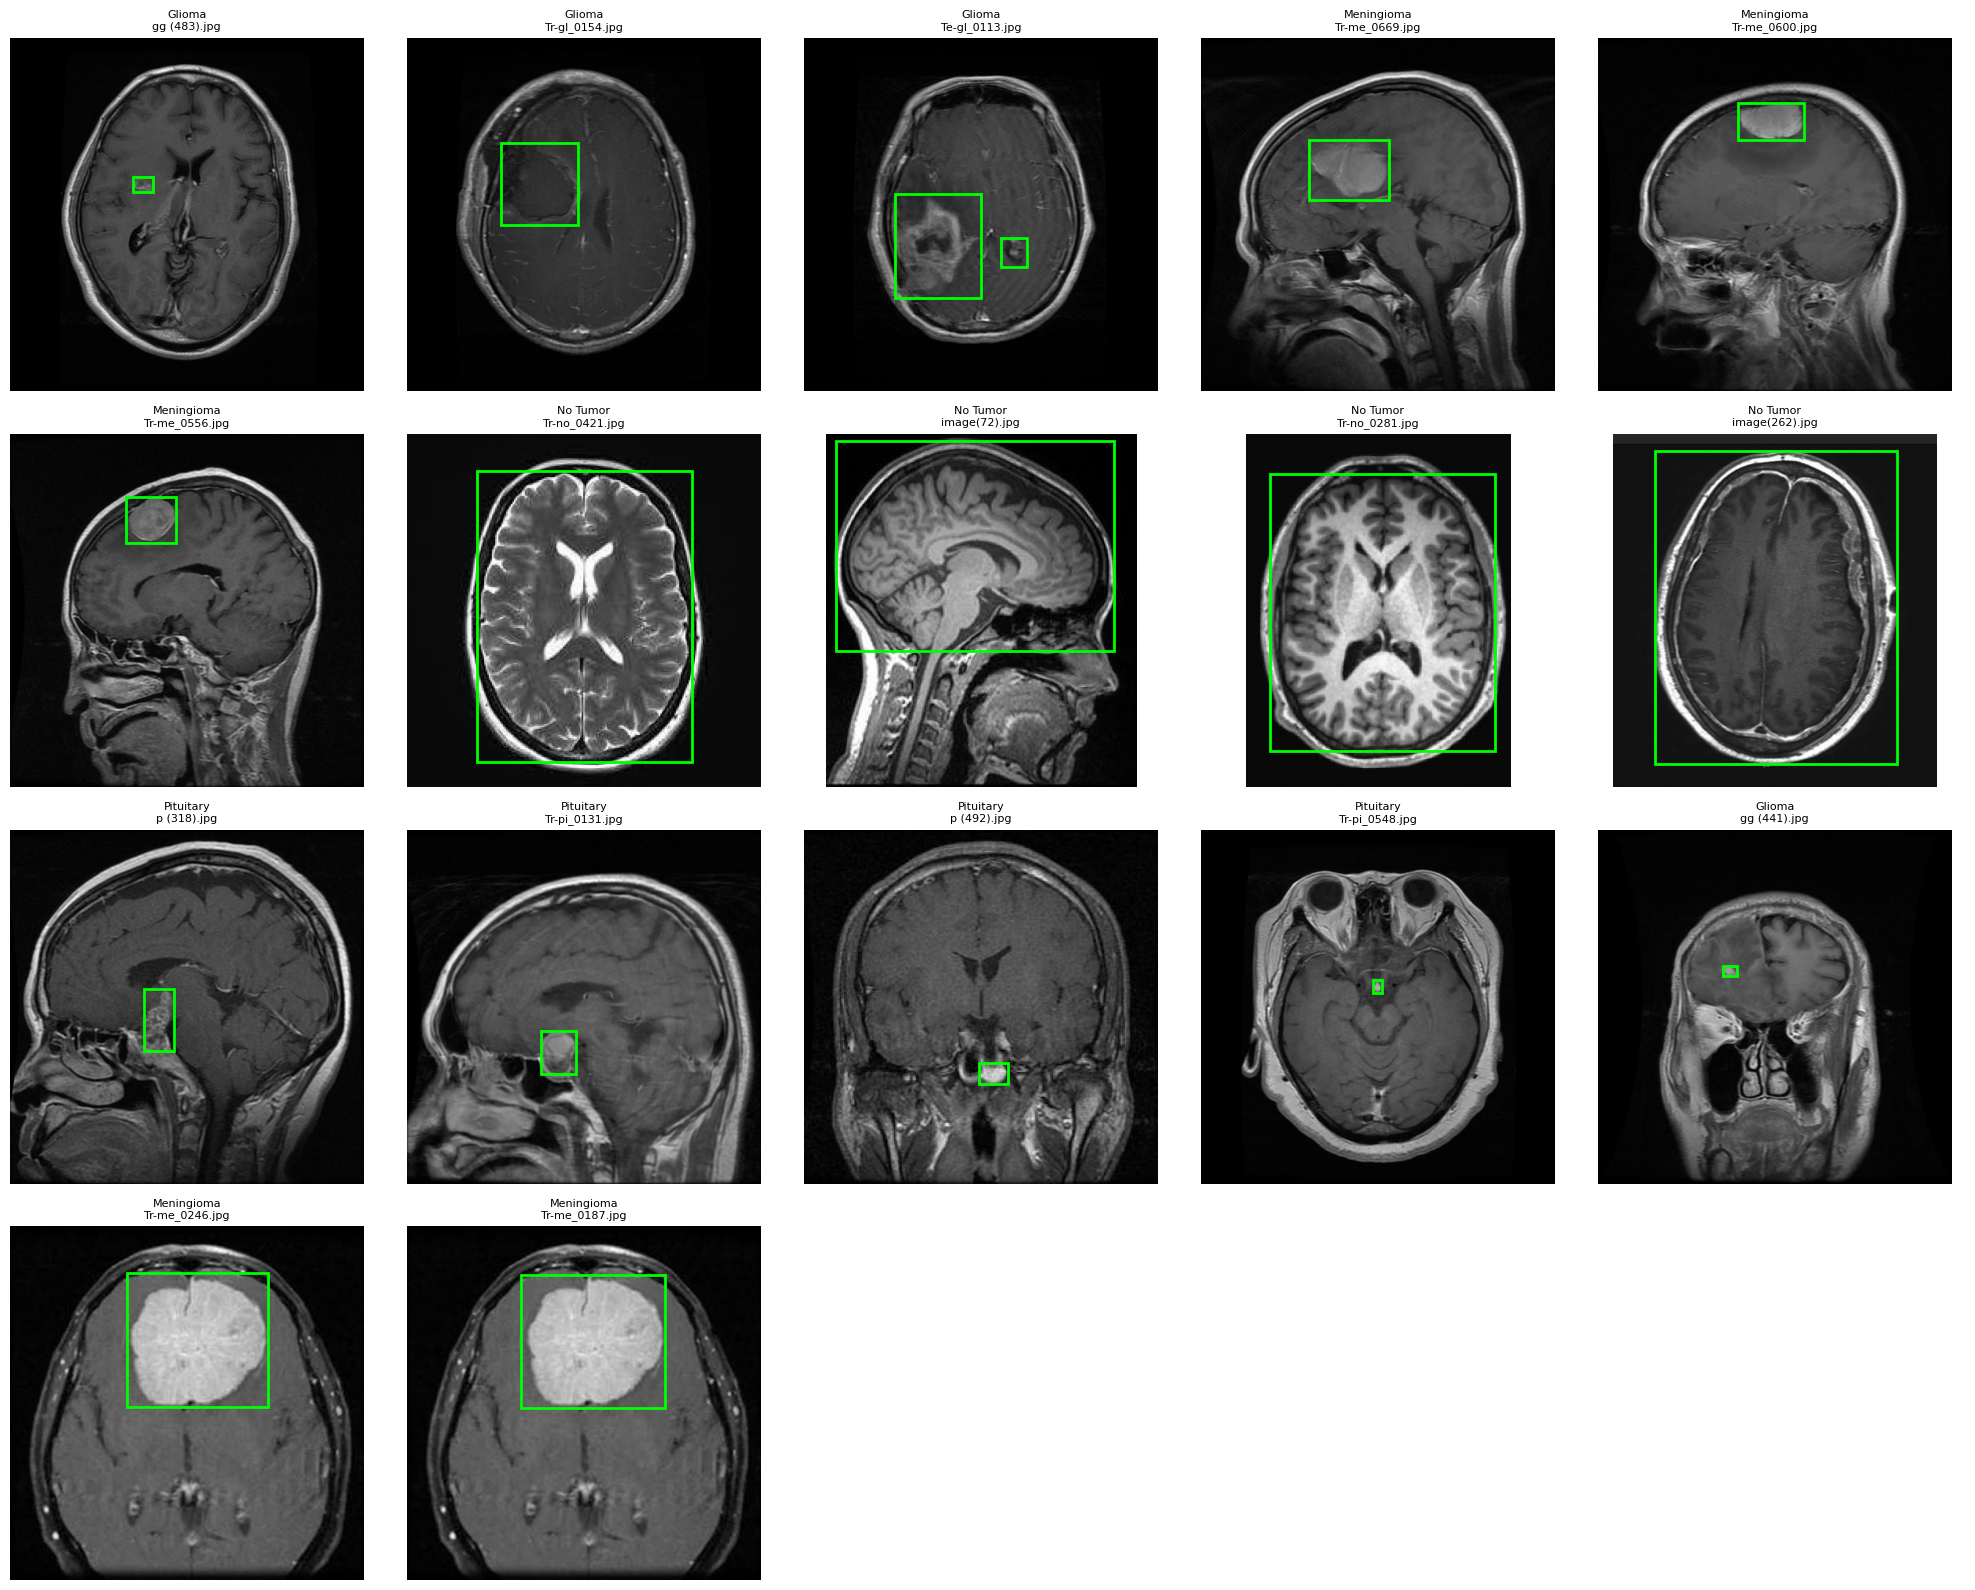

In [35]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random
from collections import defaultdict

def load_yolo_boxes(lbl_path):
    boxes = []
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                cid, xc, yc, w, h = line.split()
                boxes.append((int(cid), float(xc), float(yc), float(w), float(h)))
    return boxes

train_img_dir = FINAL_ROOT / "train" / "images"
train_lbl_dir = FINAL_ROOT / "train" / "labels"
no_tumor_id = CLASS_TO_ID["No Tumor"]

all_records = []
by_class = defaultdict(list)

for img_path in sorted(train_img_dir.glob("*.jpg")):
    boxes = load_yolo_boxes(train_lbl_dir / f"{img_path.stem}.txt")
    cid = boxes[0][0] if boxes else no_tumor_id
    rec = (img_path, boxes, cid)
    all_records.append(rec)
    by_class[cid].append(rec)

random.seed(SEED)

panel = []
for cid, name in enumerate(CLASS_NAMES):
    n_pick = 4 if cid == no_tumor_id else 3
    panel.extend(random.sample(by_class[cid], min(n_pick, len(by_class[cid]))))

boxed = [r for r in all_records if r[1] and r[2] != no_tumor_id]
by_area = sorted(boxed, key=lambda r: r[1][0][3] * r[1][0][4])
panel.extend(by_area[:2])
panel.extend(by_area[-2:])

cols = 5
rows = (len(panel) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
axes = axes.flatten()

for ax, (img_path, boxes, cid) in zip(axes, panel):
    im = Image.open(img_path)
    W, H = im.size
    ax.imshow(im, cmap="gray")
    for b_cid, xc, yc, w, h in boxes:
        x1, y1 = (xc - w / 2) * W, (yc - h / 2) * H
        ax.add_patch(patches.Rectangle((x1, y1), w * W, h * H,
                                        linewidth=2, edgecolor="lime", facecolor="none"))
    ax.set_title(f"{CLASS_NAMES[cid]}\n{img_path.name}", fontsize=8)
    ax.axis("off")

for ax in axes[len(panel):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("/content/label_inspection_panel.png", dpi=100)
plt.show()

## Training Results Analysis

In [53]:
import shutil
from pathlib import Path
from IPython.display import FileLink, display

TRAIN_RUN_DIR = Path("/content/runs/yolo11n_scratch_brain_tumor_v2")   # where training actually wrote
DL_DIR = Path("/kaggle/working")
DL_DIR.mkdir(parents=True, exist_ok=True)

for rel in ["weights/best.pt", "weights/last.pt", "results.csv"]:
    src = TRAIN_RUN_DIR / rel
    if not src.exists():
        print(f"[MISSING] {src}")
        continue
    dst = DL_DIR / src.name
    shutil.copy(src, dst)
    display(FileLink(str(dst)))

/kaggle/working/best.pt

/kaggle/working/last.pt

/kaggle/working/results.csv

In [55]:
import os, sys, platform, glob, socket
from pathlib import Path
from collections import Counter

# ---------- environment ----------
print("=" * 60); print("ENVIRONMENT"); print("=" * 60)
print("Python      :", platform.python_version())
try:
    import torch
    print("PyTorch     :", torch.__version__)
    print("CUDA        :", torch.cuda.is_available(),
          torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
except Exception as e:
    print("torch import failed:", e)
try:
    import ultralytics
    print("Ultralytics :", ultralytics.__version__)
except Exception as e:
    print("ultralytics import failed:", e)
try:
    socket.create_connection(("pypi.org", 443), timeout=5).close()
    print("Internet    : reachable")
except Exception as e:
    print("Internet    : NOT reachable ->", e)

# ---------- paths ----------
RUN_DIR   = Path("/content/runs/yolo11n_scratch_brain_tumor_v2")
DATA_ROOT = Path("/content/dataset_final")
OUT_DIR   = Path("/kaggle/working/model_output")
EXPECTED_BEST_BYTES = 5_460_378

def check(p, label):
    p = Path(p)
    if p.exists():
        extra = f"  ({p.stat().st_size:,} bytes)" if p.is_file() else ""
        print(f"[OK]      {label:12s}: {p}{extra}")
    else:
        print(f"[MISSING] {label:12s}: {p}")

print("\n" + "=" * 60); print("ARTIFACTS"); print("=" * 60)
check(RUN_DIR / "weights" / "best.pt", "best.pt")
check(RUN_DIR / "weights" / "last.pt", "last.pt")
check(RUN_DIR / "results.csv", "results.csv")
check(RUN_DIR / "args.yaml", "args.yaml")
check(DATA_ROOT / "data.yaml", "data.yaml")
best = RUN_DIR / "weights" / "best.pt"
if best.exists():
    print("best.pt size matches expected 5,460,378:", best.stat().st_size == EXPECTED_BEST_BYTES)

# ---------- dataset_final integrity ----------
print("\n" + "=" * 60); print("dataset_final"); print("=" * 60)
EXPECTED_IMGS = {"train": 2703, "valid": 579, "test": 580}
EXPECTED_BOXES = {  # from your eval outputs (val + test), train not known
    "valid": {0: 203, 1: 169, 2: 83, 3: 159},
    "test":  {0: 207, 1: 173, 2: 83, 3: 165},
}
for split, n_exp in EXPECTED_IMGS.items():
    imgs = list((DATA_ROOT / split / "images").glob("*.jpg"))
    lbls = list((DATA_ROOT / split / "labels").glob("*.txt"))
    boxes = Counter()
    for l in lbls:
        for line in l.read_text().splitlines():
            if line.strip():
                boxes[int(line.split()[0])] += 1
    ok_imgs = (len(imgs) == n_exp == len(lbls))
    print(f"{split:6s}: {len(imgs)} images / {len(lbls)} labels (expected {n_exp}) -> {'OK' if ok_imgs else 'CHECK'}")
    exp_b = EXPECTED_BOXES.get(split)
    print(f"        boxes per class id: {dict(sorted(boxes.items()))}"
          + (f"  expected {exp_b} -> {'OK' if dict(boxes) == exp_b else 'CHECK'}" if exp_b else ""))
if (DATA_ROOT / "data.yaml").exists():
    print("\ndata.yaml:\n" + (DATA_ROOT / "data.yaml").read_text())

# ---------- what is still in memory / on disk for rebuilding groups ----------
print("=" * 60); print("REBUILD INGREDIENTS"); print("=" * 60)
for v in ["new_split", "group_members", "path_to_meta", "index", "dedup_records", "dataset_path", "CLASS_TO_ID"]:
    print(f"{v:15s}:", "in memory" if v in globals() else "not defined")
cached = glob.glob("/root/.cache/kagglehub/datasets/ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes/versions/*")
print("kagglehub cache :", cached or "raw dataset not cached")
print("/kaggle/input   :", os.listdir("/kaggle/input") if os.path.exists("/kaggle/input") else "n/a")
print("model_output    :", sorted(os.listdir(OUT_DIR)) if OUT_DIR.exists() else "does not exist yet")

ENVIRONMENT
Python      : 3.12.13
PyTorch     : 2.10.0+cu128
CUDA        : True Tesla T4
Ultralytics : 8.4.175
Internet    : reachable

ARTIFACTS
[OK]      best.pt     : /content/runs/yolo11n_scratch_brain_tumor_v2/weights/best.pt  (5,460,378 bytes)
[OK]      last.pt     : /content/runs/yolo11n_scratch_brain_tumor_v2/weights/last.pt  (5,460,378 bytes)
[OK]      results.csv : /content/runs/yolo11n_scratch_brain_tumor_v2/results.csv  (18,300 bytes)
[OK]      args.yaml   : /content/runs/yolo11n_scratch_brain_tumor_v2/args.yaml  (1,708 bytes)
[OK]      data.yaml   : /content/dataset_final/data.yaml  (143 bytes)
best.pt size matches expected 5,460,378: True

dataset_final
train : 2703 images / 2703 labels (expected 2703) -> OK
        boxes per class id: {0: 970, 1: 769, 2: 385, 3: 773}
valid : 579 images / 579 labels (expected 579) -> OK
        boxes per class id: {0: 203, 1: 169, 2: 83, 3: 159}  expected {0: 203, 1: 169, 2: 83, 3: 159} -> OK
test  : 580 images / 580 labels (expected 580)

In [56]:
import csv
from PIL import Image

# invert new_split into: group_id -> clean_split, and group_id -> canonical raw path
group_to_clean_split = {}
group_to_canonical = {}
for clean_split, records in new_split.items():
    for r in records:
        group_to_clean_split[r["group_id"]] = clean_split
        group_to_canonical[r["group_id"]] = str(r["img_path"])

rows = []
missing_dims = 0

for group_id, members in group_members.items():
    clean_split = group_to_clean_split.get(group_id, "UNASSIGNED")
    canonical_path = group_to_canonical.get(group_id, "")
    for member in members:
        original_split, class_name = path_to_meta[member]
        p = Path(member)
        try:
            with Image.open(p) as im:
                w, h = im.size
                mode = im.mode
        except Exception:
            w, h, mode = None, None, None
            missing_dims += 1
        rows.append({
            "filename": p.name,
            "raw_path": member,
            "class": class_name,
            "class_id": CLASS_TO_ID[class_name],
            "group_id": group_id,
            "original_split": original_split,        # Train / valid as shipped by the dataset
            "clean_split": clean_split,               # train / valid / test after our re-split
            "is_canonical": (member == canonical_path),
            "original_width": w,
            "original_height": h,
            "original_aspect_ratio": round(w / h, 4) if w and h else None,
            "original_mode": mode,
            "original_file_bytes": p.stat().st_size if p.exists() else None,
        })

print(f"Total rows: {len(rows)} (expected 5,249)")
print(f"Rows with unreadable dimensions: {missing_dims}")
print(f"Unique groups covered: {len(set(r['group_id'] for r in rows))} (expected 3,862)")
print(f"Rows with clean_split == UNASSIGNED: {sum(1 for r in rows if r['clean_split'] == 'UNASSIGNED')}")

canonical_count = sum(1 for r in rows if r["is_canonical"])
print(f"Canonical rows: {canonical_count} (expected 3,862, one per group)")

by_clean_split = Counter(r["clean_split"] for r in rows if r["is_canonical"])
print(f"Canonical rows by clean_split: {dict(by_clean_split)}")

manifest_path = "/kaggle/working/split_manifest.csv"
with open(manifest_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    writer.writeheader()
    writer.writerows(rows)

print(f"\nWritten: {manifest_path}")

Total rows: 5249 (expected 5,249)
Rows with unreadable dimensions: 0
Unique groups covered: 3862 (expected 3,862)
Rows with clean_split == UNASSIGNED: 0
Canonical rows: 3862 (expected 3,862, one per group)
Canonical rows by clean_split: {'test': 580, 'train': 2703, 'valid': 579}

Written: /kaggle/working/split_manifest.csv


In [64]:
import yaml, json, platform
import torch, ultralytics
from pathlib import Path

RUN_DIR = Path("/content/runs/yolo11n_scratch_brain_tumor_v2")

with open(RUN_DIR / "args.yaml") as f:
    train_args = yaml.safe_load(f)

run_config = {
    "model_architecture": "yolo11n.yaml",
    "pretrained": False,
    "random_init_verified": "model.ckpt == {} confirmed before training",
    "seed": 42,
    "train_args": train_args,
    "environment": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "ultralytics": ultralytics.__version__,
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "note": "Same environment as the end-of-training validation log (Ultralytics 8.4.175, torch 2.10.0).",
    },
    "dataset": {
        "raw_images_total": 5249,
        "unique_groups_after_dedup": 3862,
        "split_method": "group-level, class-stratified, 70/15/15, seed=42",
        "split_sizes": {"train": 2703, "valid": 579, "test": 580},
    },
}

with open("/kaggle/working/run_config.json", "w") as f:
    json.dump(run_config, f, indent=2, default=str)

test_metrics_summary = {
    "split": "test",
    "note": "Evaluated once, after the val-based training/early-stopping decisions were finalized. Not tuned against.",
    "overall": {"precision": 0.950, "recall": 0.918, "mAP50": 0.950, "mAP50_95": 0.703, "macro_f1": 0.934},
    "per_class": {
        "Glioma":     {"precision": 0.882, "recall": 0.836, "AP50": 0.898, "AP50_95": 0.619, "f1": 0.858},
        "Meningioma": {"precision": 0.969, "recall": 0.910, "AP50": 0.948, "AP50_95": 0.752, "f1": 0.939},
        "No Tumor":   {"precision": 0.994, "recall": 0.976, "AP50": 0.994, "AP50_95": 0.793, "f1": 0.985},
        "Pituitary":  {"precision": 0.954, "recall": 0.952, "AP50": 0.960, "AP50_95": 0.648, "f1": 0.953},
    },
    "error_analysis": {
        "ground_truth_boxes": 628,
        "true_positives": 584,
        "wrong_class": 2,
        "false_negatives": 42,
        "false_positives": 70,
        "glioma_false_positives": {"background": 18, "poor_localization": 18, "duplicate": 13},
        "false_negatives_by_cause": {"no_prediction": 19, "poor_localization": 23},
    },
}

with open("/kaggle/working/test_metrics.json", "w") as f:
    json.dump(test_metrics_summary, f, indent=2)

print("run_config.json and test_metrics.json written.")
print(json.dumps(run_config["environment"], indent=2))

run_config.json and test_metrics.json written.
{
  "python": "3.12.13",
  "torch": "2.10.0+cu128",
  "ultralytics": "8.4.175",
  "gpu": "Tesla T4",
  "note": "Same environment as the end-of-training validation log (Ultralytics 8.4.175, torch 2.10.0)."
}


In [65]:
import shutil

OUT_DIR.mkdir(parents=True, exist_ok=True)

for src in [
    RUN_DIR / "weights" / "best.pt",
    RUN_DIR / "weights" / "last.pt",
    RUN_DIR / "results.csv",
    RUN_DIR / "args.yaml",
    "/kaggle/working/split_manifest.csv",
    "/kaggle/working/run_config.json",
    "/kaggle/working/test_metrics.json",
]:
    shutil.copy(src, OUT_DIR / Path(src).name)

print("model_output/ now contains:")
for f in sorted(OUT_DIR.iterdir()):
    print(f"  {f.name:25s} {f.stat().st_size:,} bytes")

model_output/ now contains:
  args.yaml                 1,708 bytes
  best.pt                   5,460,378 bytes
  confusion_matrix_normalized.png 160,429 bytes
  glioma_failures.png       1,157,596 bytes
  last.pt                   5,460,378 bytes
  results.csv               18,300 bytes
  run_config.json           3,189 bytes
  split_manifest.csv        1,515,327 bytes
  test_metrics.json         1,209 bytes
  training_curves.png       172,247 bytes


Ultralytics 8.4.175 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 100 layers, 2,582,932 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1298.7±693.8 MB/s, size: 34.6 KB)
val: Scanning /content/dataset_final/test/labels.cache... 580 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 580/580 270.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 8.9it/s 4.2s<0.1s
                   all        580        628       0.95      0.918       0.95      0.703
                Glioma        178        207      0.882      0.836      0.898      0.619
            Meningioma        164        173      0.969       0.91      0.948      0.752
              No Tumor         83         83      0.994      0.976      0.994      0.793
             Pituitary        154        165      0.954      0.952       0.96      0.648
Speed: 0.8ms preprocess, 2.5ms inf

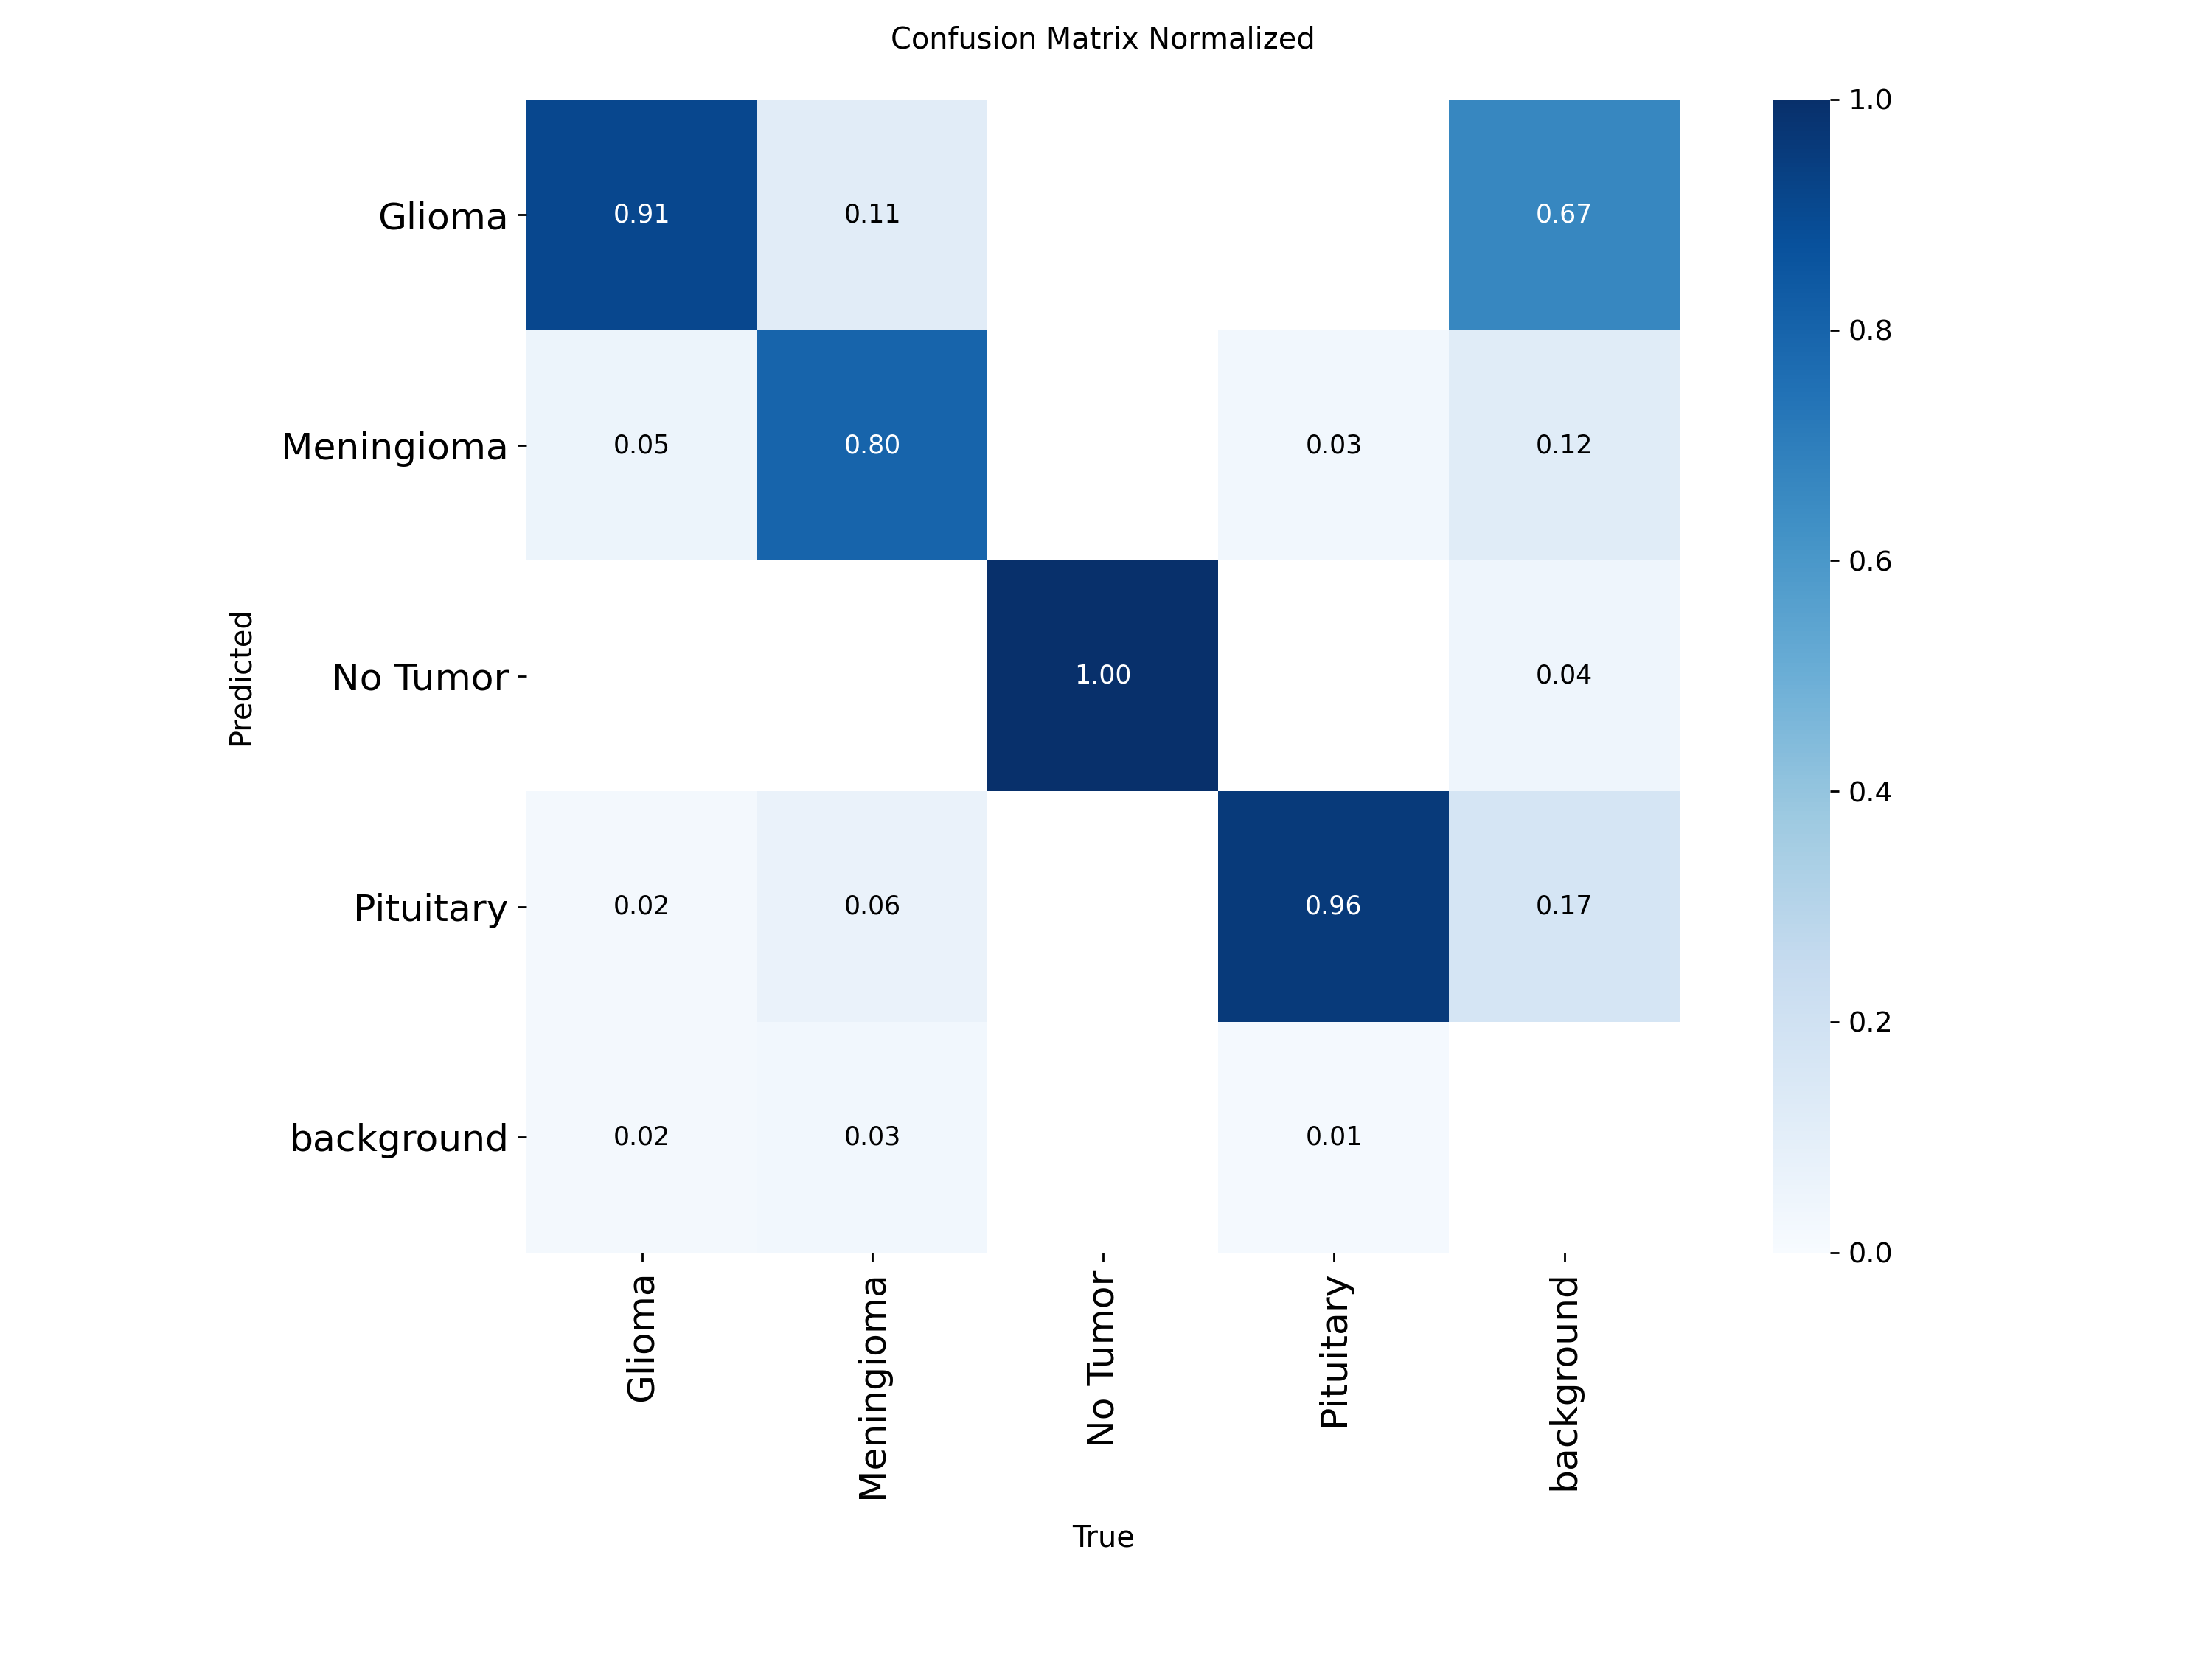

In [68]:
import shutil
from pathlib import Path
from IPython.display import Image as IPImage, display
from ultralytics import YOLO

RUN_DIR = Path("/content/runs/yolo11n_scratch_brain_tumor_v2")
OUT_DIR = Path("/kaggle/working/model_output")
OUT_DIR.mkdir(parents=True, exist_ok=True)

eval_model = YOLO(str(RUN_DIR / "weights" / "best.pt"))
test_results = eval_model.val(
    data="/content/dataset_final/data.yaml",
    split="test",
    imgsz=512,
    plots=True,
    project="/content/runs",
    name="test_eval",
    exist_ok=True,
)

cm_path = Path(test_results.save_dir) / "confusion_matrix_normalized.png"
if cm_path.exists():
    display(IPImage(filename=str(cm_path)))
    shutil.copy(cm_path, OUT_DIR / "confusion_matrix_normalized.png")
else:
    print(f"Confusion matrix not found at {cm_path}")

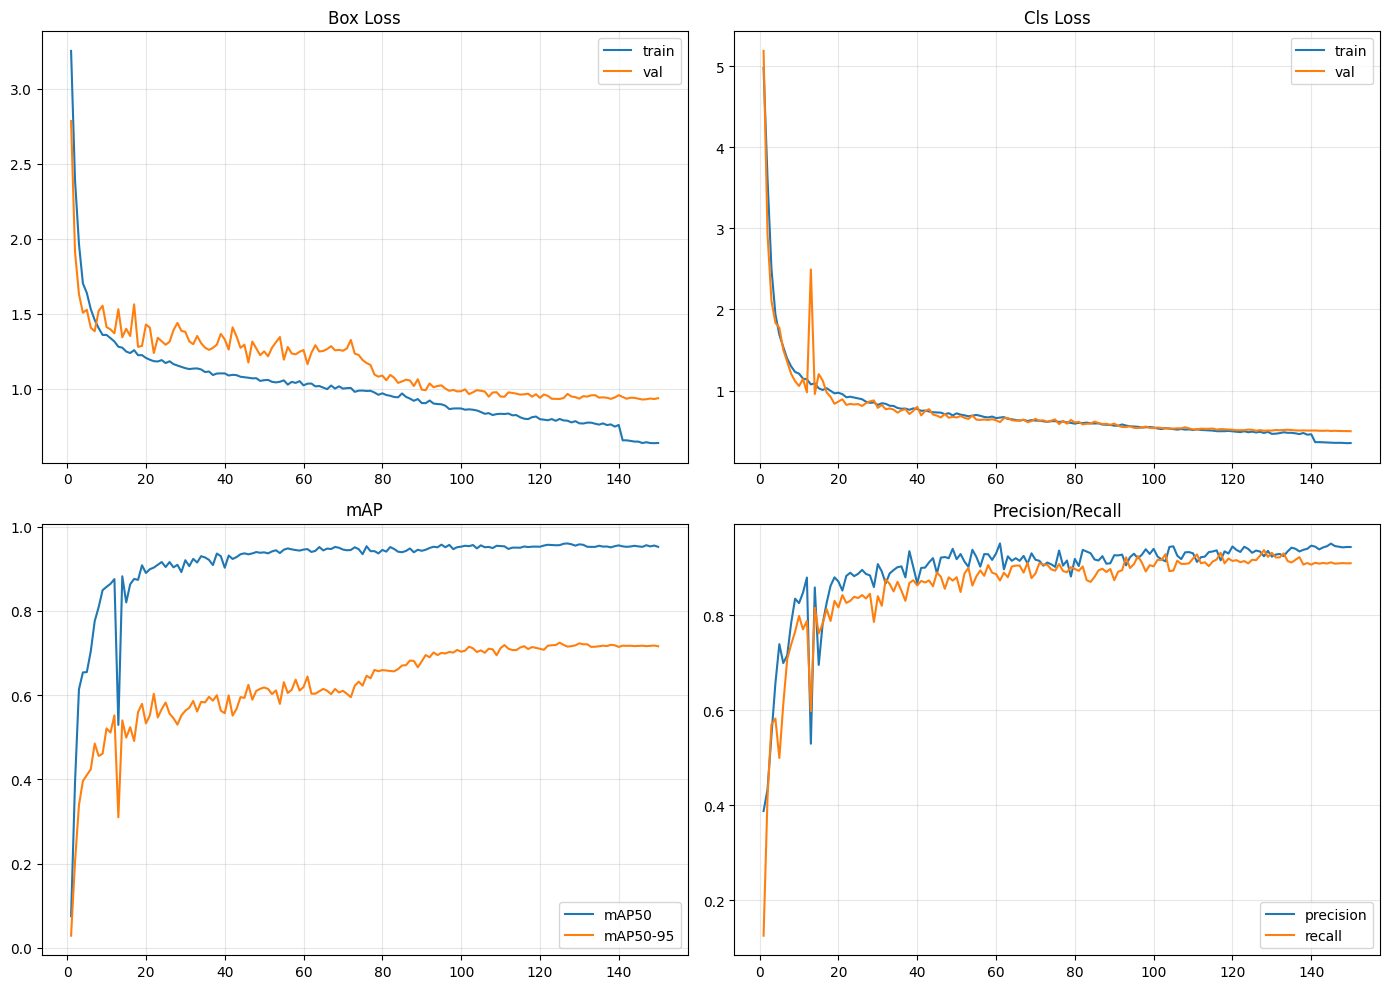

In [69]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RUN_DIR = Path("/content/runs/yolo11n_scratch_brain_tumor_v2")
OUT_DIR = Path("/kaggle/working/model_output")

df = pd.read_csv(RUN_DIR / "results.csv")
df.columns = [c.strip() for c in df.columns]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0,0].plot(df["epoch"], df["train/box_loss"], label="train"); axes[0,0].plot(df["epoch"], df["val/box_loss"], label="val")
axes[0,0].set_title("Box Loss"); axes[0,0].legend(); axes[0,0].grid(alpha=0.3)
axes[0,1].plot(df["epoch"], df["train/cls_loss"], label="train"); axes[0,1].plot(df["epoch"], df["val/cls_loss"], label="val")
axes[0,1].set_title("Cls Loss"); axes[0,1].legend(); axes[0,1].grid(alpha=0.3)
axes[1,0].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50"); axes[1,0].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
axes[1,0].set_title("mAP"); axes[1,0].legend(); axes[1,0].grid(alpha=0.3)
axes[1,1].plot(df["epoch"], df["metrics/precision(B)"], label="precision"); axes[1,1].plot(df["epoch"], df["metrics/recall(B)"], label="recall")
axes[1,1].set_title("Precision/Recall"); axes[1,1].legend(); axes[1,1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUT_DIR / "training_curves.png", dpi=120)
plt.show()

GT boxes: 628 | TP: 584 | wrong-class: 2 | FN: 42  (TP+wrong+FN = 628)
Predictions: 656 | FP: 70

FALSE POSITIVES by class x cause
  Glioma       background / no GT nearby           18
  Glioma       duplicate (GT already matched)      13
  Glioma       poor localization (0.1<=IoU<0.5)    18
  Meningioma   background / no GT nearby           2
  Meningioma   poor localization (0.1<=IoU<0.5)    4
  Pituitary    background / no GT nearby           4
  Pituitary    duplicate (GT already matched)      3
  Pituitary    poor localization (0.1<=IoU<0.5)    8

FALSE NEGATIVES by class x cause
  Glioma       no prediction at all                11
  Glioma       poor localization (0.1<=IoU<0.5)    12
  Meningioma   no prediction at all                5
  Meningioma   poor localization (0.1<=IoU<0.5)    5
  No Tumor     no prediction at all                1
  Pituitary    no prediction at all                2
  Pituitary    poor localization (0.1<=IoU<0.5)    6

Wrong-class matches (pred -> actua

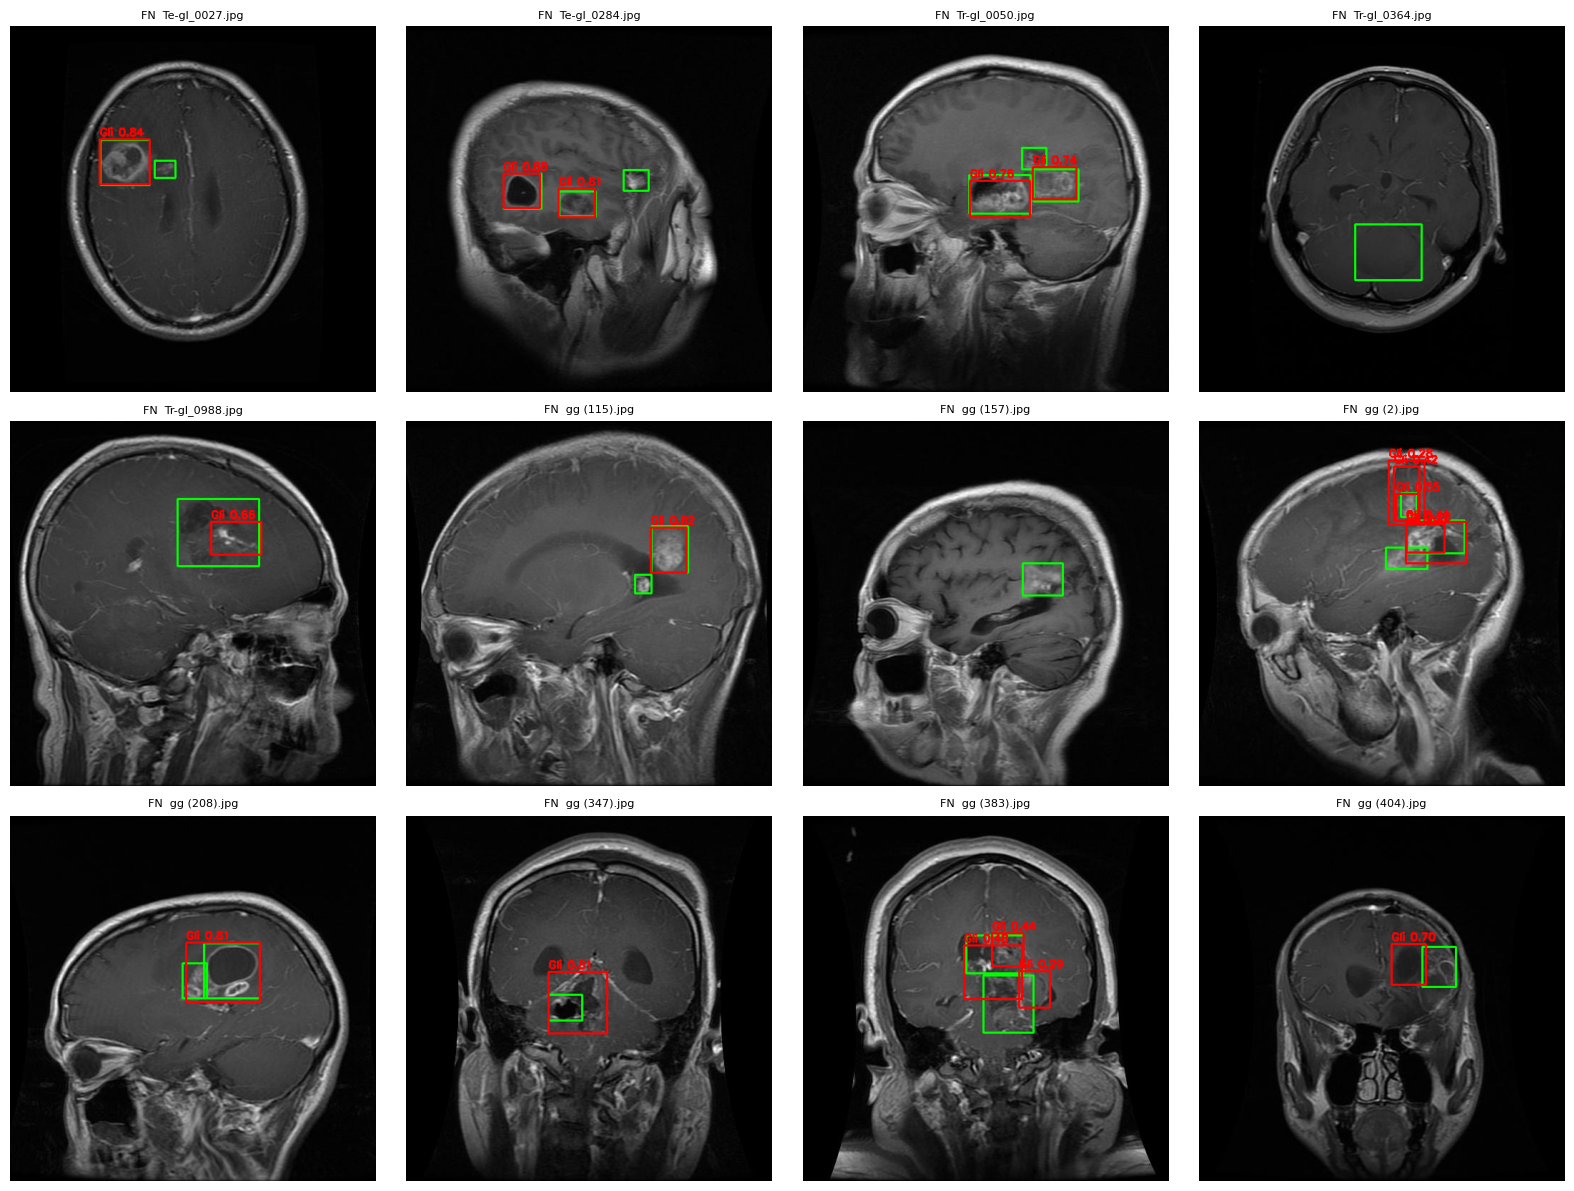

In [67]:
import cv2
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path
from PIL import Image

OUT_DIR = Path("/kaggle/working/model_output"); OUT_DIR.mkdir(parents=True, exist_ok=True)
test_lbl_dir = Path("/content/dataset_final/test/labels")
IOU_THRESH = 0.5

def iou(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0.0

preds = eval_model.predict(source="/content/dataset_final/test/images", imgsz=512,
                           conf=0.25, save=False, verbose=False)

tp, wrong_cls, fp, fn = [], [], [], []   # fp/fn entries carry a 'kind'

for r in preds:
    img_path = Path(r.path)
    with Image.open(img_path) as im:
        w, h = im.size
    gts = []
    lp = test_lbl_dir / f"{img_path.stem}.txt"
    if lp.exists():
        for line in lp.read_text().splitlines():
            if line.strip():
                c, xc, yc, bw, bh = line.split()
                xc, yc, bw, bh = map(float, (xc, yc, bw, bh))
                gts.append({"cls": int(c), "box": ((xc-bw/2)*w, (yc-bh/2)*h, (xc+bw/2)*w, (yc+bh/2)*h), "matched": False})
    ps = [{"cls": int(b.cls), "conf": float(b.conf), "box": tuple(b.xyxy[0].tolist()), "matched": False} for b in r.boxes]

    # match on IoU only (class-agnostic) so wrong-class matches are never dropped
    for p in sorted(ps, key=lambda x: -x["conf"]):
        best, bg = 0, None
        for g in gts:
            if g["matched"]: continue
            i = iou(p["box"], g["box"])
            if i > best: best, bg = i, g
        if best >= IOU_THRESH:
            bg["matched"] = p["matched"] = True
            (tp if p["cls"] == bg["cls"] else wrong_cls).append((img_path, p, bg["cls"]))

    for p in ps:
        if p["matched"]: continue
        ious = [iou(p["box"], g["box"]) for g in gts]
        m = max(ious) if ious else 0.0
        kind = "duplicate (GT already matched)" if m >= IOU_THRESH else \
               "poor localization (0.1<=IoU<0.5)" if m >= 0.1 else "background / no GT nearby"
        fp.append((img_path, p, kind, m))
    for g in gts:
        if g["matched"]: continue
        m = max([iou(p["box"], g["box"]) for p in ps], default=0.0)
        kind = "poor localization (0.1<=IoU<0.5)" if m >= 0.1 else "no prediction at all"
        fn.append((img_path, g, kind, m))

n_gt = sum(len([1 for l in (test_lbl_dir/f"{Path(r.path).stem}.txt").read_text().splitlines() if l.strip()]) for r in preds)
print(f"GT boxes: {n_gt} | TP: {len(tp)} | wrong-class: {len(wrong_cls)} | FN: {len(fn)}  (TP+wrong+FN = {len(tp)+len(wrong_cls)+len(fn)})")
print(f"Predictions: {len(tp)+len(wrong_cls)+len(fp)} | FP: {len(fp)}\n")

print("FALSE POSITIVES by class x cause")
for (c, k), n in sorted(Counter((CLASS_NAMES[p["cls"]], k) for _, p, k, _ in fp).items()):
    print(f"  {c:12s} {k:35s} {n}")
print("\nFALSE NEGATIVES by class x cause")
for (c, k), n in sorted(Counter((CLASS_NAMES[g["cls"]], k) for _, g, k, _ in fn).items()):
    print(f"  {c:12s} {k:35s} {n}")
print("\nWrong-class matches (pred -> actual, conf):")
for _, p, gc in wrong_cls:
    print(f"  {CLASS_NAMES[p['cls']]} -> {CLASS_NAMES[gc]}  conf={p['conf']:.2f}")

print("\nGlioma FP confidence buckets:")
gfp = [p["conf"] for _, p, _, _ in fp if p["cls"] == 0]
for lo, hi in [(0.25, 0.4), (0.4, 0.5), (0.5, 0.7), (0.7, 1.01)]:
    print(f"  {lo:.2f}-{hi:.2f}: {sum(lo <= c < hi for c in gfp)}")

# gallery of Glioma failures: green = GT, red = prediction
fails = [(ip, "FP", p["box"], p["conf"]) for ip, p, _, _ in fp if p["cls"] == 0]
fails += [(ip, "FN", g["box"], None) for ip, g, _, _ in fn if g["cls"] == 0]
seen, picks = set(), []
for f in sorted(fails, key=lambda x: -(x[3] or 1)):   # high-confidence FPs first, then FNs
    if (f[0], f[1]) not in seen:
        seen.add((f[0], f[1])); picks.append(f)
picks = picks[:12]

fig, axes = plt.subplots(3, 4, figsize=(16, 12)); axes = axes.flatten()
pred_by_path = {Path(r.path): r for r in preds}
for ax, (ip, kind, box, conf) in zip(axes, picks):
    img = cv2.cvtColor(cv2.imread(str(ip)), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    lp = test_lbl_dir / f"{ip.stem}.txt"
    for line in (lp.read_text().splitlines() if lp.exists() else []):
        if line.strip():
            c, xc, yc, bw, bh = line.split(); xc, yc, bw, bh = map(float, (xc, yc, bw, bh))
            cv2.rectangle(img, (int((xc-bw/2)*W), int((yc-bh/2)*H)), (int((xc+bw/2)*W), int((yc+bh/2)*H)), (0, 255, 0), 2)
    for b in pred_by_path[ip].boxes:
        x1, y1, x2, y2 = map(int, b.xyxy[0].tolist())
        cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        cv2.putText(img, f"{CLASS_NAMES[int(b.cls)][:3]} {float(b.conf):.2f}", (x1, max(y1-5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)
    ax.imshow(img); ax.set_title(f"{kind}  {ip.name}", fontsize=8); ax.axis("off")
for ax in axes[len(picks):]: ax.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "glioma_failures.png", dpi=110); plt.show()

In [70]:
!cd /kaggle/working && zip -r model_output.zip model_output && ls -la model_output.zip

  adding: model_output/ (stored 0%)
  adding: model_output/results.csv (deflated 62%)
  adding: model_output/split_manifest.csv (deflated 95%)
  adding: model_output/last.pt (deflated 11%)
  adding: model_output/best.pt (deflated 11%)
  adding: model_output/confusion_matrix_normalized.png (deflated 23%)
  adding: model_output/test_metrics.json (deflated 63%)
  adding: model_output/glioma_failures.png (deflated 2%)
  adding: model_output/run_config.json (deflated 62%)
  adding: model_output/training_curves.png (deflated 8%)
  adding: model_output/args.yaml (deflated 53%)
-rw-r--r-- 1 root root 11285774 Oct 12 05:49 model_output.zip
